# Downloading Packages

In [1]:
import os
import sys
import random
import pickle
import warnings
from datetime import datetime
from pathlib import Path
from itertools import groupby
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from tqdm import tqdm


import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Subset, DataLoader

# --- Local Module Configuration ---
FUNCTIONS_PATH = Path("/home/mokr/Reservoir_Modelling/ML_Functions/")
if str(FUNCTIONS_PATH) not in sys.path:
    sys.path.append(str(FUNCTIONS_PATH))

# Importing from your custom files
import ML_functions
from ML_functions import TensorCatchmentDataset, NSELoss, get_closest_landcover_year
from ML_Models import LSTM_With_Embedding, LSTMModel, HydraModel
from ML_Plots import display_results_table, plot_score_cdfs

from ML_Training import (
    train_model,
    validate_model_scores,
    run_model_pipeline,
    process_validation_batches,
    collect_validation_results,
    get_basin_name,
    lagged_model_predictions,
    calculate_rolling_metrics,
)

from ML_Metrics import (
    calculate_nse,
    calculate_nnse,
    calculate_kge_components,
    calculate_bias,
    get_consecutive_gauge_indices, 
    get_basin_name,
)

# Download catchment data

In [2]:

## Not using river flow
No_Flow_Reservoir_Embedded_LSTM = torch.load("/home/mokr/Reservoir_Modelling/CamelsGB_Models/Reservoir/2003_No_Lat_Reservoir_LSTM_Numlayers1_LSTMhs256_Embhs64_Embos16_Epochs0_Gamma0.8_0.001_0.4.pt",
    weights_only=False,
    map_location=torch.device("cpu"),
)

No_Flow_NonReservoir_Embedded_LSTM = torch.load(    "/home/mokr/Reservoir_Modelling/CamelsGB_Models/Natural/2003_No_Lat_Natural_LSTM_FlowFalse_Numlayers2_LSTMhs256_Embhs64_Embos16_Epochs2_Gamma0.95_0.001_0.4.pt",
    weights_only=False,
    map_location=torch.device("cpu"),
)

No_Flow_Full_Embedded_LSTM = torch.load(    "/home/mokr/Reservoir_Modelling/CamelsGB_Models/Full/2003_No_Lat__Full_LSTM_Numlayers2_LSTMhs128_Embhs128_Embos32_Epochs0_Gamma0.95.pt_0.001_0.1",
    weights_only=False,
    map_location=torch.device("cpu"),
)

full_base_path = "/home/mokr/Reservoir_Modelling/CamelsGB_Models/Hydra/2003_No_Lat_Full_Hydra_LSTM_Numlayers1_LSTMhs256_Embhs128_Embos16_BodyOut128_MainEp3_ResEp3_ResLR0.001_Gamma0.95_0.001_0.001"


No_Flow_Full_Hydra_Body = torch.load(
    f"{full_base_path}_Body.pt", weights_only=False, map_location=torch.device("cpu")
)
No_Flow_Full_Hydra_Head = torch.load(
    f"{full_base_path}_Main_Head.pt", weights_only=False, map_location=torch.device("cpu")
)
No_Flow_Full_Hydra_ResHead = torch.load(
    f"{full_base_path}_Res_Embedding_Head.pt",
    weights_only=False,
    map_location=torch.device("cpu"),
)

No_Flow_Full_Hydra_Main = HydraModel(No_Flow_Full_Hydra_Body, No_Flow_Full_Hydra_Head)

In [3]:
No_Flow_Full_Hydra_Main

HydraModel(
  (body): LSTM_With_Embedding(
    (static_embedding): Static_Embedding(
      (layers): Sequential(
        (0): Linear(in_features=111, out_features=128, bias=True)
        (1): ReLU()
        (2): Linear(in_features=128, out_features=16, bias=True)
      )
    )
    (lstm): LSTMModel(
      (lstm): LSTM(32, 256, batch_first=True, dropout=0.3)
      (dropout): Dropout(p=0.3, inplace=False)
      (fc): Linear(in_features=256, out_features=128, bias=True)
    )
  )
  (head_default): LSTMModel(
    (lstm): LSTM(128, 256, batch_first=True, dropout=0.3)
    (dropout): Dropout(p=0.3, inplace=False)
    (fc): Linear(in_features=256, out_features=1, bias=True)
  )
)

In [4]:
No_Flow_Full_Embedded_LSTM

LSTM_With_Embedding(
  (static_embedding): Static_Embedding(
    (layers): Sequential(
      (0): Linear(in_features=111, out_features=128, bias=True)
      (1): ReLU()
      (2): Linear(in_features=128, out_features=32, bias=True)
    )
  )
  (lstm): LSTMModel(
    (lstm): LSTM(48, 128, num_layers=2, batch_first=True, dropout=0.1)
    (dropout): Dropout(p=0.1, inplace=False)
    (fc): Linear(in_features=128, out_features=1, bias=True)
  )
)

In [5]:
test_non_res_tensor_data = torch.load(
    "/perm/mokr/CamelsGB_V2/no_lat_test_non_res_tensor_data.pt"
)
test_non_res_dataset = TensorCatchmentDataset(test_non_res_tensor_data)

BATCH_SIZE = 1
NUM_WORKERS = 1
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

test_non_reservoir_dataloader = DataLoader(
    test_non_res_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS
)  # , pin_memory=True, persistent_workers=True

test_res_tensor_data = torch.load("/perm/mokr/CamelsGB_V2/no_lat_test_res_tensor_data.pt")
test_res_dataset = TensorCatchmentDataset(test_res_tensor_data)


test_reservoir_dataloader = DataLoader(
    test_res_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS
)  # , pin_memory=True, persistent_workers=True

In [9]:
import torch

def check_tensor_memory(obj, name="Data"):
    """Recursively calculates the true RAM footprint of PyTorch tensors."""
    def get_size(o):
        if torch.is_tensor(o):
            # True size = number of elements * bytes per element
            return o.element_size() * o.nelement()
        elif isinstance(o, dict):
            return sum(get_size(v) for v in o.values())
        elif isinstance(o, (list, tuple)):
            return sum(get_size(v) for v in o)
        else:
            return 0 # Ignoring negligible Python object overhead

    size_in_bytes = get_size(obj)
    size_in_mb = size_in_bytes / (1024 ** 2)
    size_in_gb = size_in_bytes / (1024 ** 3)
    
    print(f"[{name}] True RAM Footprint: {size_in_mb:.2f} MB ({size_in_gb:.4f} GB)")

# --- Run it on your loaded data ---
test_non_res_tensor_data = torch.load("/perm/mokr/CamelsGB_V2/no_lat_test_non_res_tensor_data.pt")

check_tensor_memory(test_non_res_tensor_data, "test_non_res_tensor_data")

[test_non_res_tensor_data] True RAM Footprint: 1260.28 MB (1.2307 GB)


In [24]:
len(test_non_res_tensor_data['target'])

201325

In [6]:
test_non_res_tensor_metadata = torch.load(
    "/perm/mokr/CamelsGB_V2/test_non_res_tensor_metadata.pt"
)

test_res_tensor_metadata = torch.load(
    "/perm/mokr/CamelsGB_V2/test_res_tensor_metadata.pt"
)

In [7]:
def calculate_rolling_metrics(results_dict, metadata, window_size=90):
    """
    Calculate rolling window metrics per gauge independently.
    
    Args:
        results_dict: dict [model_name]['Prediction'/'Truth'] -> list of tensors
        metadata:     dict with 'gauge_id' and 'init_date' lists (same length as predictions)
        window_size:  number of timesteps per rolling window (default 90)
    
    Returns:
        dict of {model_name: {metric_name: [values], 'gauge_id': [], 'init_date': []}}
    """
    metrics = defaultdict(lambda: defaultdict(list))
    model_names = list(results_dict.keys())

    # Group indices by gauge
    gauge_ids = metadata['gauge_id']
    init_dates = metadata['init_date']

    gauge_to_indices = defaultdict(list)
    for idx, gauge_id in enumerate(gauge_ids):
        gauge_to_indices[gauge_id].append(idx)

    for model_name in model_names:
        predictions = results_dict[model_name]['Prediction']
        truths      = results_dict[model_name]['Truth']

        for gauge_id, indices in gauge_to_indices.items():
            num_windows = len(indices) - window_size + 1

            if num_windows <= 0:
                continue  # Skip gauges with fewer timesteps than window

            for i in range(num_windows):
                window_indices = indices[i : i + window_size]

                output_forecast = torch.stack([predictions[j] for j in window_indices]).squeeze()
                target_forecast = torch.stack([truths[j]      for j in window_indices]).squeeze()

                nse  = calculate_nse(output_forecast, target_forecast)
                nnse = calculate_nnse(output_forecast, target_forecast)
                bias = calculate_bias(output_forecast, target_forecast)

                correlation, alpha, beta = calculate_kge_components(output_forecast, target_forecast)
                kge = 1 - np.sqrt(
                    (correlation - 1) ** 2 + (alpha - 1) ** 2 + (beta - 1) ** 2
                )

                metrics[model_name]["NSE"].append(nse.item())
                metrics[model_name]["NNSE"].append(nnse.item())
                metrics[model_name]["KGE_alpha"].append(alpha.item())
                metrics[model_name]["KGE_beta"].append(beta.item())
                metrics[model_name]["KGE_correlation"].append(correlation.item())
                metrics[model_name]["KGE"].append(kge.item())
                metrics[model_name]["bias"].append(bias.item())
                # Track which gauge/date each window corresponds to
                metrics[model_name]["gauge_id"].append(gauge_id)
                metrics[model_name]["init_date"].append(init_dates[indices[i]])

    return metrics



In [8]:
# IDs, val as scotland
test_res_tensor_metadata = torch.load(
    "/perm/mokr/CamelsGB_V2/test_res_tensor_metadata.pt"
)
test_non_res_tensor_metadata = torch.load(
    "/perm/mokr/CamelsGB_V2/test_non_res_tensor_metadata.pt"
)


# 1. Pre-calculate the mapping once
gauge_index_map = get_consecutive_gauge_indices(test_res_tensor_metadata)

gauge_loaders = {}
for gid, indices in gauge_index_map.items():
    # Use Subset to point to the specific data for this gauge
    gauge_subset = Subset(test_non_res_dataset, indices)

    # Create the loader (Batch size = total gauge samples for single-pass evaluation)
    gauge_loaders[gid] = DataLoader(
        gauge_subset, batch_size=len(indices), shuffle=False
    )

from collections import defaultdict


# Download Models

In [9]:
## Not using river flow
No_Flow_Reservoir_Embedded_LSTM = torch.load("/home/mokr/Reservoir_Modelling/CamelsGB_Models/Reservoir/2003_No_Lat_Reservoir_LSTM_Numlayers1_LSTMhs256_Embhs64_Embos16_Epochs0_Gamma0.8_0.001_0.4.pt",
    weights_only=False,
    map_location=torch.device("cpu"),
)


No_Flow_NonReservoir_Embedded_LSTM = torch.load(
    "/home/mokr/Reservoir_Modelling/CamelsGB_Models/Natural/2003_No_Lat_Natural_LSTM_FlowFalse_Numlayers2_LSTMhs256_Embhs64_Embos16_Epochs2_Gamma0.95_0.001_0.4.pt",
    weights_only=False,
    map_location=torch.device("cpu"),
)


No_Flow_Full_Embedded_LSTM = torch.load(
    "/home/mokr/Reservoir_Modelling/CamelsGB_Models/Full/2003_No_Lat__Full_LSTM_Numlayers2_LSTMhs128_Embhs128_Embos32_Epochs0_Gamma0.95.pt_0.001_0.1",
    weights_only=False,
    map_location=torch.device("cpu"),
)


# base_path = "/home/mokr/Reservoir_Modelling/CamelsGB_Models/Hydra/Hydra_LSTM_Numlayers1_LSTMhs128_Embhs64_Embos16_BodyOut128_MainEp1_ResEp2_ResLR0.001_Gamma0.8"
# No_Flow_Hydra_Body = torch.load(
#     f"{base_path}_Body.pt", weights_only=False, map_location=torch.device("cpu")
# )
# No_Flow_Hydra_Head = torch.load(
#     f"{base_path}_Main_Head.pt", weights_only=False, map_location=torch.device("cpu")
# )
# No_Flow_Hydra_ResHead = torch.load(
#     f"{base_path}_Res_Embedding_Head.pt",
#     weights_only=False,
#     map_location=torch.device("cpu"),
# )
# No_Flow_Hydra_Main = HydraModel(No_Flow_Hydra_Body, No_Flow_Hydra_Head)

full_base_path = "/home/mokr/Reservoir_Modelling/CamelsGB_Models/Hydra/2003_No_Lat_Full_Hydra_LSTM_Numlayers1_LSTMhs256_Embhs128_Embos16_BodyOut128_MainEp3_ResEp3_ResLR0.001_Gamma0.95_0.001_0.001"

No_Flow_Full_Hydra_Body = torch.load(
    f"{full_base_path}_Body.pt", weights_only=False, map_location=torch.device("cpu")
)
No_Flow_Full_Hydra_Head = torch.load(
    f"{full_base_path}_Main_Head.pt", weights_only=False, map_location=torch.device("cpu")
)
No_Flow_Full_Hydra_ResHead = torch.load(
    f"{full_base_path}_Res_Embedding_Head.pt",
    weights_only=False,
    map_location=torch.device("cpu"),
)
No_Flow_Full_Hydra_Main = HydraModel(No_Flow_Full_Hydra_Body, No_Flow_Full_Hydra_Head)


## Using River Flow
Reservoir_Embedded_LSTM = torch.load(
    "/home/mokr/Reservoir_Modelling/CamelsGB_Models/Using_Flow/Reservoir/2003_No_Lat_Reservoir_LSTM_Numlayers2_LSTMhs256_Embhs128_Embos16_Epochs3_Gamma0.95_0.001_0.1.pt",
    weights_only=False,
    map_location=torch.device("cpu"),
)


NonReservoir_Embedded_LSTM = torch.load(
    "/home/mokr/Reservoir_Modelling/CamelsGB_Models/Using_Flow/Natural/2003_No_Lat_Natural_LSTM_Numlayers2_LSTMhs256_Embhs128_Embos32_Epochs5_Gamma0.95_0.001_0.1.pt",
    weights_only=False,
    map_location=torch.device("cpu"),
)
Full_Embedded_LSTM = torch.load(
    "/home/mokr/Reservoir_Modelling/CamelsGB_Models/Using_Flow/Full/2003_No_Lat__Full_LSTM_Numlayers2_LSTMhs256_Embhs128_Embos16_Epochs1_Gamma0.95_0.001_0.1.pt",
    weights_only=False,
    map_location=torch.device("cpu"),
)



base_path = "/home/mokr/Reservoir_Modelling/CamelsGB_Models/Using_Flow/Hydra/2003_No_Lat_Full_Hydra_LSTM_Numlayers1_LSTMhs256_Embhs128_Embos16_BodyOut128_MainEp8_ResEp1_ResLR0.001_Gamma0.95_0.001_0.001"
Hydra_Body = torch.load(
    f"{base_path}_Body.pt", weights_only=False, map_location=torch.device("cpu")
)
Hydra_Head = torch.load(
    f"{base_path}_Main_Head.pt", weights_only=False, map_location=torch.device("cpu")
)
Hydra_ResHead = torch.load(
    f"{base_path}_Res_Embedding_Head.pt",
    weights_only=False,
    map_location=torch.device("cpu"),
)
Hydra_Main = HydraModel(Hydra_Body, Hydra_Head)

full_base_path = "/home/mokr/Reservoir_Modelling/CamelsGB_Models/Hydra/2003_No_Lat_Full_Hydra_LSTM_Numlayers1_LSTMhs256_Embhs128_Embos16_BodyOut128_MainEp3_ResEp3_ResLR0.0001_Gamma0.95_0.001_0.0001"

No_Flow_Full_Hydra_NonResHead = torch.load(
    f"{full_base_path}_NonRes_Embedding_Head.pt",
    weights_only=False,
    map_location=torch.device("cpu"),
)



In [10]:
MODEL_NAME_MAP = {
    "Reservoir Embedded LSTM": "Reservoir LSTM",
    "NonReservoir Embedded LSTM": "Non-Reservoir LSTM",
    "Full Embedded LSTM": "Full LSTM",
    "Hydra-LSTM: Main": "Hydra: Full",
    "Hydra-LSTM: Reservoir Head": "Hydra-LSTM: Res-Head",
    "Hydra-LSTM: Non-Reservoir Head": "Hydra-LSTM: NonRes-Head",

    
}

model_names = [
    "Reservoir_Embedded_LSTM",
    "NonReservoir_Embedded_LSTM",
    "Full_Embedded_LSTM",
    "Hydra_Main",
    "Hydra_ResHead",
    "Hydra_NonResHead",
    
]

no_flow_models = [
    No_Flow_Reservoir_Embedded_LSTM,
    No_Flow_NonReservoir_Embedded_LSTM,
    No_Flow_Full_Embedded_LSTM,
    No_Flow_Full_Hydra_Main,
    [No_Flow_Full_Hydra_Body, No_Flow_Full_Hydra_ResHead],
    [No_Flow_Full_Hydra_Body, No_Flow_Full_Hydra_NonResHead],
]


MODEL_COLORS = {
    "Reservoir":                 "#4477AA",  # blue
    "Non-Reservoir":             "#EE6677",  # red
    "Full LSTM":                 "#228833",  # green
    "Hydra: Main":               "#CCBB44",  # yellow
    "Hydra: Res Head":           "#66CCEE",  # cyan
    "Hydra: Non-Res Head":       "#AA3377",  # purple
}


MODEL_COLORS = {
    "Reservoir":           "#0F6E56",  # teal dark  ─┐ reservoir family
    "Hydra: Res Head":     "#5DCAA5",  # teal light ─┘

    "Non-Reservoir":       "#534AB7",  # purple dark  ─┐ non-reservoir family
    "Hydra: Non-Res Head": "#AFA9EC",  # purple light ─┘

    "Full LSTM":           "#993C1D",  # coral dark  ─┐ whole-network family
    "Hydra: Main":         "#F0997B",  # coral light ─┘
}

In [11]:
"""import pickle

# Save to pickle file
with open('/home/mokr/Reservoir_Modelling/Catchment_Lists/basins_and_dates.pkl', 'wb') as f:
    pickle.dump(Split_Metadata, f)"""

"import pickle\n\n# Save to pickle file\nwith open('/home/mokr/Reservoir_Modelling/Catchment_Lists/basins_and_dates.pkl', 'wb') as f:\n    pickle.dump(Split_Metadata, f)"

In [12]:
from sklearn.preprocessing import StandardScaler

temporal_scalers = joblib.load("/home/mokr/Reservoir_Modelling/scaler_hydromet.pkl")

scaler_river = StandardScaler()

# Extract the mean, variance, and scale for the -2nd column
scaler_river.mean_ = temporal_scalers.mean_[[-2]]
scaler_river.var_ = temporal_scalers.var_[[-2]]
scaler_river.scale_ = temporal_scalers.scale_[[-2]]



/usr/local/apps/python3/3.13.13-01/lib/python3.13/site-packages/sklearn/base.py:463: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.7.2 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


# Run Models

In [16]:
max_batches = 1e2
TIME_INTERVAL = 30
warmup = 10

print("Reservoirs - No Flow")

no_flow_reservoir_validation_results = validate_model_scores(
    model_names,
    no_flow_models,
    test_reservoir_dataloader,
    warmup,
    streamflow_scaler=scaler_river,
    device="cpu",
    time_interval=TIME_INTERVAL,
    max_batches=max_batches,
    use_flow=False,
)

print("Reservoirs - Flow")

flow_reservoir_validation_results = validate_model_scores(
    model_names,
    flow_models,
    test_reservoir_dataloader,
    warmup,
    streamflow_scaler=scaler_river,
    device="cpu",
    time_interval=TIME_INTERVAL,
    max_batches=max_batches,
    use_flow=True,
)

print("Natural - No Flow")

no_flow_nonreservoir_validation_results = validate_model_scores(
    model_names,
    no_flow_models,
    test_non_reservoir_dataloader,
    warmup,
    streamflow_scaler=scaler_river,
    device="cpu",
    time_interval=TIME_INTERVAL,
    max_batches=max_batches,
    use_flow=False,
)

print("Natural - Flow")

flow_nonreservoir_validation_results = validate_model_scores(
    model_names,
    flow_models,
    test_non_reservoir_dataloader,
    warmup,
    streamflow_scaler=scaler_river,
    device="cpu",
    time_interval= TIME_INTERVAL,
    max_batches=max_batches,
    use_flow=True,
)

Reservoirs - No Flow


Processing batches:   0%|          | 100/212421 [00:06<3:39:47, 16.10batch/s]


Reached maximum number of batches (100.0). Stopping.
Reservoirs - Flow


Processing batches:   0%|          | 100/212421 [00:09<5:36:24, 10.52batch/s]


Reached maximum number of batches (100.0). Stopping.
Natural - No Flow


Processing batches:   0%|          | 100/212421 [00:05<3:00:48, 19.57batch/s]


Reached maximum number of batches (100.0). Stopping.
Natural - Flow


Processing batches:   0%|          | 100/212421 [00:05<3:02:46, 19.36batch/s]

Reached maximum number of batches (100.0). Stopping.


In [17]:
max_batches = 2e2
warmup = 88
print("Running no flow reservoir lagged predictions...")
no_flow_reservoir_lagged = lagged_model_predictions(
    model_names,
    no_flow_models,
    test_reservoir_dataloader,
    streamflow_scaler=scaler_river,
    warmup=warmup,
    device="cpu",
    time_interval=TIME_INTERVAL,
    max_batches=max_batches,
    use_flow=False,
)
print("Running flow reservoir lagged predictions...")
flow_reservoir_lagged = lagged_model_predictions(
    model_names,
    flow_models,
    test_reservoir_dataloader,
    streamflow_scaler=scaler_river,
    warmup=warmup,
    device="cpu",
    time_interval=TIME_INTERVAL,
    max_batches=max_batches,
    use_flow=True,
)

print("Running no flow non-reservoir lagged predictions...")
no_flow_nonreservoir_lagged = lagged_model_predictions(
    model_names,
    no_flow_models,
    test_non_reservoir_dataloader,
    streamflow_scaler=scaler_river,
    warmup=warmup,
    device="cpu",
    time_interval=TIME_INTERVAL,
    max_batches=max_batches,
    use_flow=False,
)
print("Running flow non-reservoir lagged predictions...")
flow_nonreservoir_lagged = lagged_model_predictions(
    model_names,
    flow_models,
    test_non_reservoir_dataloader,
    streamflow_scaler=scaler_river,
    warmup=warmup,
    device="cpu",
    time_interval=TIME_INTERVAL,
    max_batches=max_batches,
    use_flow=True,
)


Running no flow reservoir lagged predictions...


Processing batches:   0%|          | 200/212421 [00:08<2:33:53, 22.99batch/s]


Reached maximum number of batches (200.0). Stopping.
Running flow reservoir lagged predictions...


Processing batches:   0%|          | 200/212421 [00:26<7:44:27,  7.62batch/s]


Reached maximum number of batches (200.0). Stopping.
Running no flow non-reservoir lagged predictions...


Processing batches:   0%|          | 200/212421 [00:40<12:01:04,  4.91batch/s]


Reached maximum number of batches (200.0). Stopping.
Running flow non-reservoir lagged predictions...


Processing batches:   0%|          | 200/212421 [01:02<18:31:16,  3.18batch/s]

Reached maximum number of batches (200.0). Stopping.


# Load Results

In [13]:
with open('/home/mokr/Reservoir_Modelling/results/trimmed_landcover_validation_results.pkl', 'rb') as f:
    validation_results = pickle.load(f)

In [14]:
import shelve
import gc

# SHELVE_METRICS_PATH = "/home/mokr/Reservoir_Modelling/results/no_lat_rolling_metrics"
# SHELVE_RESULTS_PATH  = "/home/mokr/Reservoir_Modelling/results/no_lat_lagged_results"



SHELVE_METRICS_PATH = "/home/mokr/Reservoir_Modelling/results/1505_no_lat_rolling_metrics" # 2204
SHELVE_RESULTS_PATH  = "/home/mokr/Reservoir_Modelling/results/1505_no_lat_lagged_results" #2204


# Load lagged results
print("Loading lagged results from shelve...")
with shelve.open(SHELVE_RESULTS_PATH, flag='r') as db:
    no_flow_reservoir_lagged    = dict(db.get("no_flow_reservoir",    {}))
    # flow_reservoir_lagged       = dict(db.get("flow_reservoir",       {}))
    no_flow_nonreservoir_lagged = dict(db.get("no_flow_nonreservoir", {}))
    # flow_nonreservoir_lagged    = dict(db.get("flow_nonreservoir",    {}))
gc.collect()


# Load all metrics
print("Loading metrics from shelve...")
with shelve.open(SHELVE_METRICS_PATH, flag='r') as db:
    no_flow_reservoir_metrics    = dict(db["no_flow_reservoir"])
    # flow_reservoir_metrics       = dict(db["flow_reservoir"])
    no_flow_nonreservoir_metrics = dict(db["no_flow_nonreservoir"])
    # flow_nonreservoir_metrics    = dict(db["flow_nonreservoir"])
gc.collect()



Loading lagged results from shelve...
Loading metrics from shelve...


0

In [15]:
def display_results_table(results, use_median=False, confidence_interval=None, n_bootstrap=1000, to_list = False):
    """
    Display validation results as a formatted table.
    
    Parameters:
    results (dict): Dictionary containing model names as keys and dicts of scores as values.
    use_median (bool): If True, calculates the median instead of the mean. Default is False.
    confidence_interval (float | None): If provided, compute a confidence interval at this level
        (e.g. 0.95 for 95%). Uses bootstrapping for the median and a t-distribution for the mean.
    n_bootstrap (int): Number of bootstrap resamples when computing CI for the median. Default 1000.
    """
    agg_func = np.median if use_median else np.mean
    metrics = ["NSE", "NNSE", "KGE", "KGE_alpha", "KGE_beta", "KGE_correlation", "bias"]

    def compute_ci_bootstrap(values, level, n_resamples):
        """Bootstrap percentile CI."""
        values = np.asarray(values)
        rng = np.random.default_rng()
        boot_stats = np.array([
            agg_func(rng.choice(values, size=len(values), replace=True))
            for _ in range(n_resamples)
        ])
        alpha = 1 - level
        lower = np.percentile(boot_stats, 100 * alpha / 2)
        upper = np.percentile(boot_stats, 100 * (1 - alpha / 2))
        return lower, upper

    def compute_ci_t(values, level):
        """t-distribution CI for the mean."""
        from scipy import stats
        n = len(values)
        se = stats.sem(values)
        interval = stats.t.interval(level, df=n - 1, loc=np.mean(values), scale=se)
        return interval[0], interval[1]

    summary = {}
    for model_name, scores in results.items():
        summary[model_name] = {}
        for metric in metrics:

            if to_list:
                vals = np.asarray(scores[metric].to_list())
            else:
                vals = np.asarray(scores[metric])
            point = agg_func(vals)

            if confidence_interval is not None:
                if use_median:
                    lo, hi = compute_ci_bootstrap(vals, confidence_interval, n_bootstrap)
                else:
                    lo, hi = compute_ci_t(vals, confidence_interval)
                summary[model_name][metric] = (point, lo, hi)
            else:
                summary[model_name][metric] = point

    # Build a DataFrame of point estimates for ranking, and a display DataFrame
    point_df = pd.DataFrame(
        {model: {m: v[0] if confidence_interval else v for m, v in scores.items()}
         for model, scores in summary.items()}
    ).T

    if confidence_interval is not None:
        display_df = pd.DataFrame(
            {model: {m: f"{v[0]:.2f} [{v[1]:.2f}, {v[2]:.2f}]"
                     for m, v in scores.items()}
             for model, scores in summary.items()}
        ).T
    else:
        display_df = point_df.copy()

    # Determine best model for each metric using point estimates
    best_models = {
        "NSE":             point_df["NSE"].idxmax(),
        "NNSE":            point_df["NNSE"].idxmax(),
        "KGE":             point_df["KGE"].idxmax(),
        "KGE_correlation": point_df["KGE_correlation"].idxmax(),
        "KGE_alpha":       point_df["KGE_alpha"].apply(lambda x: abs(x - 1)).idxmin(),
        "KGE_beta":        point_df["KGE_beta"].apply(lambda x: abs(x - 1)).idxmin(),
        "bias":            point_df["bias"].apply(abs).idxmin(),
    }

    def highlight_best(col):
        best_model = best_models[col.name]
        return ["font-weight: bold" if idx == best_model else "" for idx in col.index]

    fmt = "{}" if confidence_interval else "{:.2f}"
    styled_df = display_df.style.apply(highlight_best, axis=0).format(fmt)
    return styled_df

In [16]:
no_flow_reservoir_metrics['Reservoir_Embedded_LSTM']['NSE'][0]
# len(no_flow_reservoir_metrics['Hydra_Main']['NSE'])


0.8677668571472168

In [17]:
no_flow_reservoir_metrics.keys()


dict_keys(['Reservoir_Embedded_LSTM', 'NonReservoir_Embedded_LSTM', 'Full_Embedded_LSTM', 'Hydra_Main', 'Hydra_ResHead', 'Hydra_NonResHead'])

In [18]:
# Initialize the new dictionary for the combined metrics
no_flow_grouped_metrics = {}

# Define the new model names exactly as they will appear in your final table
grouped_models = [
    "Specialist LSTMs", 
    "Hydra-LSTM: Specialists", 
    "Full LSTM",
    "Hydra-LSTM: Main", 
]

for model in grouped_models:
    no_flow_grouped_metrics[model] = {}

# Extract the list of metrics (NSE, KGE, etc.) to loop through
# This assumes all models evaluated the exact same metrics
metrics = no_flow_reservoir_metrics['Reservoir_Embedded_LSTM'].keys()

for metric in metrics:
    
    # 1. Specialist LSTMs
    # Route Reservoir LSTM to reservoir gauges, Non-Reservoir LSTM to non-reservoir gauges
    res_specialist = no_flow_reservoir_metrics['Reservoir_Embedded_LSTM'][metric]
    nonres_specialist = no_flow_nonreservoir_metrics['NonReservoir_Embedded_LSTM'][metric]
    no_flow_grouped_metrics["Specialist LSTMs"][metric] = list(res_specialist) + list(nonres_specialist)

    # 2. Hydra-LSTM: Specialists
    # Route Res-Head to reservoir gauges, Non-Res-Head to non-reservoir gauges
    # (Update the string keys here if they differ in your dictionary)
    res_hydra = no_flow_reservoir_metrics['Hydra_ResHead'][metric] 
    nonres_hydra = no_flow_nonreservoir_metrics['Hydra_NonResHead'][metric]
    no_flow_grouped_metrics["Hydra-LSTM: Specialists"][metric] = list(res_hydra) + list(nonres_hydra)

    # 3. Hydra-LSTM: Main
    # Evaluated across ALL gauges (combine both sets)
    res_main = no_flow_reservoir_metrics['Hydra_Main'][metric]
    nonres_main = no_flow_nonreservoir_metrics['Hydra_Main'][metric]
    no_flow_grouped_metrics["Hydra-LSTM: Main"][metric] = list(res_main) + list(nonres_main)

    # 4. Full LSTM
    # Evaluated across ALL gauges (combine both sets)
    res_full = no_flow_reservoir_metrics['Full_Embedded_LSTM'][metric]
    nonres_full = no_flow_nonreservoir_metrics['Full_Embedded_LSTM'][metric]
    no_flow_grouped_metrics["Full LSTM"][metric] = list(res_full) + list(nonres_full)

In [23]:
# Display the final combined table
display_results_table(
    no_flow_grouped_metrics, 
    use_median=True, 
    confidence_interval=0.95, 
    n_bootstrap=100
)

,NSE,NNSE,KGE,KGE_alpha,KGE_beta,KGE_correlation,bias
Specialist LSTMs,"0.73 [0.73, 0.73]","0.79 [0.79, 0.79]","0.78 [0.78, 0.78]","0.94 [0.94, 0.94]","1.00 [1.00, 1.00]","0.93 [0.93, 0.93]","0.00 [0.00, 0.00]"
Hydra-LSTM: Specialists,"0.72 [0.72, 0.72]","0.78 [0.78, 0.78]","0.78 [0.78, 0.78]","0.97 [0.97, 0.97]","1.01 [1.01, 1.01]","0.93 [0.93, 0.93]","0.01 [0.01, 0.01]"
Full LSTM,"0.73 [0.73, 0.73]","0.79 [0.79, 0.79]","0.76 [0.76, 0.76]","0.94 [0.94, 0.94]","1.03 [1.03, 1.03]","0.93 [0.93, 0.93]","0.04 [0.04, 0.04]"
Hydra-LSTM: Main,"0.72 [0.72, 0.72]","0.78 [0.78, 0.78]","0.78 [0.78, 0.78]","0.97 [0.97, 0.97]","1.00 [1.00, 1.00]","0.93 [0.93, 0.93]","0.00 [0.00, 0.00]"


# Display Table

In [20]:
display_results_table(no_flow_reservoir_metrics, use_median = True, confidence_interval=0.95, n_bootstrap=10)

,NSE,NNSE,KGE,KGE_alpha,KGE_beta,KGE_correlation,bias
Reservoir_Embedded_LSTM,"0.74 [0.74, 0.74]","0.79 [0.79, 0.79]","0.81 [0.81, 0.81]","0.94 [0.94, 0.94]","1.02 [1.02, 1.02]","0.92 [0.92, 0.92]","0.04 [0.04, 0.04]"
NonReservoir_Embedded_LSTM,"0.57 [0.57, 0.57]","0.70 [0.70, 0.70]","0.69 [0.69, 0.69]","1.06 [1.06, 1.06]","1.10 [1.10, 1.10]","0.90 [0.90, 0.90]","0.16 [0.16, 0.16]"
Full_Embedded_LSTM,"0.74 [0.74, 0.74]","0.79 [0.79, 0.79]","0.78 [0.78, 0.78]","0.94 [0.94, 0.94]","1.03 [1.03, 1.03]","0.93 [0.93, 0.93]","0.05 [0.05, 0.05]"
Hydra_Main,"0.73 [0.73, 0.73]","0.79 [0.79, 0.79]","0.80 [0.80, 0.80]","0.98 [0.98, 0.98]","1.00 [1.00, 1.00]","0.93 [0.93, 0.93]","0.00 [0.00, 0.00]"
Hydra_ResHead,"0.73 [0.73, 0.73]","0.79 [0.79, 0.79]","0.80 [0.80, 0.81]","0.98 [0.98, 0.98]","1.01 [1.01, 1.02]","0.93 [0.93, 0.93]","0.03 [0.03, 0.03]"
Hydra_NonResHead,"0.72 [0.72, 0.72]","0.78 [0.78, 0.78]","0.80 [0.80, 0.80]","1.04 [1.04, 1.04]","1.00 [1.00, 1.00]","0.93 [0.93, 0.93]","-0.01 [-0.01, -0.01]"


In [21]:
display_results_table(no_flow_nonreservoir_metrics, use_median = True, confidence_interval=0.95, n_bootstrap=100)

,NSE,NNSE,KGE,KGE_alpha,KGE_beta,KGE_correlation,bias
Reservoir_Embedded_LSTM,"0.58 [0.58, 0.58]","0.70 [0.70, 0.70]","0.63 [0.63, 0.63]","0.99 [0.99, 0.99]","0.91 [0.91, 0.91]","0.89 [0.89, 0.89]","-0.12 [-0.12, -0.11]"
NonReservoir_Embedded_LSTM,"0.72 [0.72, 0.72]","0.78 [0.78, 0.78]","0.75 [0.75, 0.75]","0.94 [0.94, 0.94]","0.98 [0.98, 0.98]","0.93 [0.93, 0.93]","-0.03 [-0.03, -0.02]"
Full_Embedded_LSTM,"0.72 [0.72, 0.72]","0.78 [0.78, 0.78]","0.75 [0.74, 0.75]","0.94 [0.93, 0.94]","1.03 [1.03, 1.03]","0.93 [0.93, 0.93]","0.03 [0.03, 0.03]"
Hydra_Main,"0.71 [0.71, 0.71]","0.77 [0.77, 0.77]","0.77 [0.76, 0.77]","0.96 [0.95, 0.96]","1.00 [1.00, 1.00]","0.93 [0.93, 0.93]","0.00 [0.00, 0.00]"
Hydra_ResHead,"0.70 [0.70, 0.70]","0.77 [0.77, 0.77]","0.73 [0.73, 0.73]","0.99 [0.98, 0.99]","0.97 [0.97, 0.97]","0.93 [0.93, 0.93]","-0.04 [-0.05, -0.04]"
Hydra_NonResHead,"0.71 [0.70, 0.71]","0.77 [0.77, 0.77]","0.76 [0.76, 0.76]","0.97 [0.97, 0.97]","1.00 [0.99, 1.00]","0.93 [0.93, 0.93]","-0.00 [-0.01, -0.00]"


In [22]:
display_results_table(flow_reservoir_metrics, use_median =True)

NameError: name 'flow_reservoir_metrics' is not defined

In [ ]:
display_results_table(flow_nonreservoir_metrics, use_median =True)

# Getting Gradients

In [ ]:
def compute_gradient_importance(
    model_names,
    models,
    dataloader,
    warmup,
    feature_names_static,
    feature_names_temporal,
    device="cpu",
    time_interval=180,
    max_batches=None,
    use_flow=False,
    aggregation="mean_abs",
):
    if not isinstance(models, list):
        models = [models]

    for model in models:
        if isinstance(model, list):
            for sub_model in model:
                sub_model.eval()
        else:
            model.eval()

    records = []
    global_sample_idx = 0

    progress_bar = tqdm(
        dataloader, desc="Processing batches", unit="batch", mininterval=time_interval
    )

    for batch_idx, batch in enumerate(progress_bar):
        if max_batches is not None and batch_idx >= max_batches:
            print(f"Reached maximum number of batches ({max_batches}). Stopping.")
            break

        static_input_raw   = batch["static"].to(device)
        temporal_input_raw = batch["temporal"]
        target = batch["target"]

        if use_flow:
            previous_flow      = target[:, :-1].unsqueeze(-1)
            temporal_input_raw = temporal_input_raw[:, :-1, :]
            temporal_input_raw = torch.cat([temporal_input_raw, previous_flow], dim=-1)
            target = target[:, 1:]

        temporal_input_raw = temporal_input_raw.to(device)
        batch_size = temporal_input_raw.shape[0]

        for model_name, model in zip(model_names, models):

            # Fresh leaves with gradient tracking for both input types
            static_input   = static_input_raw.detach().requires_grad_(True)
            temporal_input = temporal_input_raw.detach().requires_grad_(True)

            with torch.enable_grad():
                raw_output = run_model_pipeline(model, static_input, temporal_input)
                output_warmup_excluded = raw_output[:, warmup:].squeeze(-1)  # [B, T]

                # Per-sample mean output in scaled space: [B]
                per_sample_output = output_warmup_excluded.mean(dim=1)

            for s in range(batch_size):
                # Zero grads on both inputs
                if static_input.grad is not None:
                    static_input.grad.zero_()
                if temporal_input.grad is not None:
                    temporal_input.grad.zero_()

                per_sample_output[s].backward(retain_graph=True)

                # static_input.grad:   [B, F_static]  → slice sample s → [F_static]
                # temporal_input.grad: [B, T, F_temp]  → slice sample s → [T, F_temp]
                g_static   = static_input.grad[s].detach()    # [F_static]
                g_temporal = temporal_input.grad[s].detach()  # [T, F_temp]

                if aggregation == "mean_abs":
                    static_feat_grad   = g_static.abs()             # [F_static] — no time dim to reduce
                    temporal_feat_grad = g_temporal.abs() #.amax(dim=0)  # [F_temp] Takes the one with the maximum value
                elif aggregation == "rms":
                    static_feat_grad   = g_static.pow(2).sqrt()
                    temporal_feat_grad = g_temporal.pow(2).sqrt() #.mean(dim=0).sqrt()
                elif aggregation == "mean_signed":
                    static_feat_grad   = g_static
                    temporal_feat_grad = g_temporal#.mean(dim=0)
                else:
                    raise ValueError(f"Unknown aggregation: {aggregation}")
                
                # Create flattened dictionary for temporal features across all time steps
                temporal_dict = {}
                T_steps = temporal_feat_grad.shape[0]
                for i, k in enumerate(feature_names_temporal):
                    for t in range(T_steps):
                        temporal_dict[f"temporal__{k}_day_{t}"] = temporal_feat_grad[t, i].item()
  
                records.append({
                    "model":      model_name,
                    "sample_idx": global_sample_idx + s,
                    **{f"static__{k}":   v.item() for k, v in zip(feature_names_static,   static_feat_grad.cpu())},
                    **temporal_dict,
                })

        global_sample_idx += batch_size

    df = pd.DataFrame(records).set_index(["model", "sample_idx"])
    return df.sort_index()


    

In [ ]:
with open("/home/mokr/Reservoir_Modelling/Normalised_Temporal_Data.pkl", "rb") as f:
    temporal_data = pickle.load(f)

static_variables = pd.read_csv(
    "/perm/mokr/Scaled_CamelsGB_V2/normalised_static_data.csv", dtype={"gauge_id": str}
)



static_variables = static_variables.set_index("gauge_id")
static_variables = static_variables.select_dtypes(include=[np.number])

EXCLUDE_STATIC = {

    "gauge_lon", "gauge_northing", "hourly_flow_perc_complete",
    "gauge_easting", "tawc_missing", 
    "monthly_gwlevel_period_start", "monthly_gwlevel_period_end",
    "gw_well_easting", "gw_well_datum", "gw_well_northing", "gw_well_name", 
    "daily_gwlevel_period_end", "gw_well_id", "daily_gwlevel_period_start",
    'q5_uncert_upper', 'q25_uncert_upper', 'q50_uncert_upper', 'q75_uncert_upper', 'q95_uncert_upper', 'q99_uncert_upper',
    'q5_uncert_lower', 'q25_uncert_lower', 'q50_uncert_lower', 'q75_uncert_lower', 'q95_uncert_lower', 'q99_uncert_lower',
    'q_mean', 'Q5', 'Q95', 'stream_elas', 'slope_fdc', 'baseflow_index', 'baseflow_index_ceh', 'hfd_mean',
    'high_q_freq', 'high_q_dur', 'low_q_freq', 'low_q_dur', 'zero_q_freq', 
    'runoff_ratio', 'daily_flow_perc_complete', 'daily_flow_extrap_dur',
    'max_hourly_flow', 'max_gauging_flow', 'max_daily_flow', 'hourly_flow_extrap_dur', 
    
}


# EXCLUDE_STATIC = {

#     "gauge_lon", "gauge_northing", "hourly_flow_perc_complete",
#     "gauge_easting", "tawc_missing", 
#     "monthly_gwlevel_period_start", "monthly_gwlevel_period_end",
#     "gw_well_easting", "gw_well_datum", "gw_well_northing",
#     "daily_gwlevel_period_end", "gw_well_id", "daily_gwlevel_period_start",
#     "gw_well_name",
# }


# "max_gauging_flow_date", "gauge_id", "benchmark_catch", "gauge_name"

static_variables = (
    static_variables
    .drop(columns=list(EXCLUDE_STATIC))
)


In [ ]:
LANDCOVER_PREFIXES = [
    'dwood_perc', 'ewood_perc', 'grass_perc', 'shrub_perc',
    'crop_perc', 'urban_perc', 'inwater_perc', 'bares_perc'
]
AVAILABLE_LANDCOVER_YEARS = [1990, 2015, 2017, 2018, 2019, 2020, 2021, 2022]



# ── Temporal feature names ──────────────────────────────────────────────────
goals = ["discharge_spec_x", "discharge_spec_y", "discharge_vol_x", "discharge_vol_y", 'date']
first_gauge = next(iter(temporal_data))
feature_names_temporal = [
    c for c in temporal_data[first_gauge].columns if c not in goals
]

# ── Static feature names ────────────────────────────────────────────────────
# landcover_cols = [
#     c for c in static_variables.columns
#     if any(c.startswith(p) for p in LANDCOVER_PREFIXES)
# ]
# non_landcover_cols = [c for c in static_variables.columns if c not in landcover_cols]

# # Use a representative year for the landcover names (same logic as preprocess_to_tensors)
# representative_year = get_closest_landcover_year(pd.Timestamp.now().year)
# landcover_cols_named = [f"{p}_{representative_year}" for p in LANDCOVER_PREFIXES]

# feature_names_static = non_landcover_cols + landcover_cols_named


feature_names_static = [c for c in static_variables.columns]

In [ ]:
feature_names_temporal

In [ ]:
BATCH_SIZE = 1
warmup = 89
test_reservoir_dataloader = DataLoader(
    test_res_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS
)  # , pin_memory=True, persistent_workers=True

In [ ]:

df = compute_gradient_importance(
    model_names=model_names,
    models=no_flow_models,
    dataloader=test_reservoir_dataloader,
    warmup=warmup,
    feature_names_static=feature_names_static,
    feature_names_temporal=feature_names_temporal,
    device="cpu",
    time_interval=2,
    max_batches=10,
    use_flow=False,
    aggregation="mean_abs",
)



In [ ]:
# df.to_csv("/home/mokr/Reservoir_Modelling/Gradients_Importance_For_Ieuan_1903.csv")
df

In [ ]:
mean_importance = df.groupby("sample_idx").mean().mean()  # mean over samples, then models
print(mean_importance.sort_values(ascending=False).to_string())

In [ ]:
import re

# 2. Filter for the specific feature columns
feature = "precipitation_cehgear"
precip_cols = [c for c in df.columns if f"temporal__{feature}_day_" in c]

# 3. Sort columns numerically by day so the x-axis is in chronological order
precip_cols = sorted(precip_cols, key=lambda x: int(re.search(r"_day_(\d+)", x).group(1)))

# 4. Calculate the mean importance
# Option A: Global mean across all models and samples (similar to your snippet)
global_mean_importance = df[precip_cols].mean()

# Option B: Mean importance separated by model
model_mean_importance = df.groupby("model")[precip_cols].mean()

# 5. Extract the day numbers for the x-axis
days = [int(re.search(r"_day_(\d+)", c).group(1)) for c in precip_cols]

# --- Plotting ---
plt.figure(figsize=(12, 6))

# Uncomment this line if you ONLY want the global average line:
# plt.plot(days, global_mean_importance.values, label="Global Mean", color="black", linewidth=2.5)

# Plotting each model separately:
for model_name in model_mean_importance.index:
    plt.plot(days, model_mean_importance.loc[model_name].values, label=model_name, linewidth=1.5)

plt.title(f"Temporal Gradient Importance: {feature}")
plt.xlabel("Days into the Sequence")
plt.ylabel("Mean Absolute Gradient (Importance)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()


# Averaging scores per gauge

In [ ]:

results_dict = {
    'no_flow_reservoir': no_flow_reservoir_metrics,
    # 'flow_reservoir': flow_reservoir_metrics,
    'no_flow_nonreservoir': no_flow_nonreservoir_metrics,
    # 'flow_nonreservoir': flow_nonreservoir_metrics,
}

avg_metrics_by_results = {}

for results_name, results_metrics in results_dict.items():
    avg_metrics_by_model = {}
    
    for model, metrics_data in results_metrics.items():
        df = pd.DataFrame(metrics_data)
        
        if 'init_date' in df.columns:
            df = df.drop(columns=['init_date'])
            
        if 'gauge_id' in df.columns:
            avg_df = df.groupby('gauge_id').mean(numeric_only=True)
            avg_metrics_by_model[model] = avg_df
        else:
            print(f"Notice: 'gauge_id' not found for model '{model}' in '{results_name}'. Skipping.")
    
    avg_metrics_by_results[results_name] = avg_metrics_by_model

In [ ]:
avg_metrics_by_results.keys()

In [ ]:
avg_metrics_by_results['no_flow_reservoir']['Reservoir_Embedded_LSTM']['KGE'].to_list()

display_results_table(avg_metrics_by_results['no_flow_nonreservoir'], use_median = True, confidence_interval=0.90, n_bootstrap=1000, to_list = True)

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.cm as cm

def plot_cdfs_individual(
    avg_metrics_by_results,
    metrics=["KGE"], #"NSE", 
    figsize_per_plot= (12, 6),
    title_names=None,
    model_names=None,
    model_colors=None,
):
    """
    Plot and SAVE individual CDFs of specified metrics for each results dictionary.
    """
    # ── font sizes ────────────────────────────────────────────────────────────
    fs_title  = 20
    fs_xlabel = 18
    fs_ylabel = fs_xlabel
    fs_tick   = 16
    fs_legend = 18
    # ─────────────────────────────────────────────────────────────────────────

    if model_colors is None:
        # Assuming MODEL_COLORS is defined globally in your script
        model_colors = MODEL_COLORS 

    results_names = list(avg_metrics_by_results.keys())
    n_rows = len(results_names)

    if title_names is None:
        title_names = results_names
    if len(title_names) != n_rows:
        raise ValueError(
            f"title_names has {len(title_names)} entries but there are {n_rows} results dicts."
        )

    # fallback colour cycle for any model not in model_colors
    fallback_colors = cm.tab10(np.linspace(0, 0.9, 10))
    
    for results_name, display_title in zip(results_names, title_names):

        model_dict = avg_metrics_by_results[results_name]
        models = list(model_dict.keys())

        if model_names is None:
            display_model_names = models
        else:
            if len(model_names) != len(models):
                raise ValueError(
                    f"model_names has {len(model_names)} entries but '{results_name}' "
                    f"has {len(models)} models."
                )
            display_model_names = model_names

        for metric in metrics:
            
            # 1. Create a NEW figure for this specific metric and dataset
            fig, ax = plt.subplots(figsize=figsize_per_plot)
            fallback_idx = 0 

            for model, display_name in zip(models, display_model_names):
                df = model_dict[model]

                if metric not in df.columns:
                    print(
                        f"Warning: '{metric}' not found for model '{model}' "
                        f"in '{results_name}'. Skipping."
                    )
                    continue

                # resolve colour: use model_colors dict, fall back to tab10
                if display_name in model_colors:
                    color = model_colors[display_name]
                else:
                    color = fallback_colors[fallback_idx % 10]
                    fallback_idx += 1

                values = df[metric].dropna().values
                
                # Skip plotting if the data is entirely empty
                if len(values) == 0:
                    continue
                    
                sorted_vals = np.sort(values)
                cdf = np.arange(1, len(sorted_vals) + 1) / len(sorted_vals)

                ax.plot(sorted_vals, cdf, label=display_name, color=color, linewidth=1.8)

            ax.set_xlabel(metric, fontsize=fs_xlabel)
            ax.set_ylabel("CDF", fontsize=fs_ylabel)
            ax.set_title(f"{display_title}  —  {metric}", fontsize=fs_title, fontweight="bold")
            ax.tick_params(labelsize=fs_tick)
            ax.set_ylim(0, 1)
            ax.grid(True, linestyle="--", alpha=0.4)
            ax.spines[["top", "right"]].set_visible(False)

            # 1. Extract the handles and labels
            handles, labels = ax.get_legend_handles_labels()
            
            # Only draw legends if there is actually data on the plot
            if handles:
                # 2. Create the top legend (First 3 models)
                leg1 = ax.legend(
                    handles[:3], labels[:3],
                    fontsize=fs_legend, 
                    loc="upper center",          
                    bbox_to_anchor=(0.5, -0.13), # Sit right below the plot
                    ncol=3,                      
                    framealpha=0.7
                )
                
                # 3. Add the top legend manually
                ax.add_artist(leg1)
                
                # 4. Create the bottom legend (All remaining models)
                if len(handles) > 3:
                    remaining_count = len(handles[3:])
                    leg2 = ax.legend(
                        handles[3:], labels[3:],
                        fontsize=fs_legend, 
                        loc="upper center",          
                        bbox_to_anchor=(0.5, -0.25), # Push this one down below the first legend
                        ncol=remaining_count,        
                        framealpha=0.7
                    )
            
            # Clean up the layout
            fig.tight_layout()
            
            # 5. Save the individual plot!
            # Cleans up the filename to avoid weird spaces or characters
            safe_results_name = results_name.replace(" ", "_").replace("/", "_")
            filename = f"CDF_{safe_results_name}_{metric}.png"
            
            # bbox_inches='tight' is CRITICAL here so your bottom legend isn't cut off!
            fig.savefig(filename, dpi=300, bbox_inches='tight')
            
            # 6. Close the figure to free memory before the loop starts again
            plt.close(fig)
            
            print(f"Saved: {filename}")



plot_cdfs_individual(
        avg_metrics_by_results,
        title_names=[
            "No flow – Reservoir",
            # "Flow – Reservoir",
            "No flow – Non-Reservoir",
            # "Flow – Non-Reservoir",
        ],
        model_names=model_names,
        model_colors=MODEL_COLORS,
    )

In [ ]:
def plot_cdfs(
    avg_metrics_by_results,
    metrics=["KGE"],
    figsize_per_plot=(9, 6),
    title_names=None,
    model_names=None,
    model_colors=None,
    xlim = -0.5,
):
    # ── font sizes ────────────────────────────────────────────────────────────
    fs_title  = 20
    fs_xlabel = 24
    fs_ylabel = fs_xlabel
    fs_tick   = 16
    fs_legend = 18
    # ─────────────────────────────────────────────────────────────────────────
    if model_colors is None:
        model_colors = MODEL_COLORS
    results_names = list(avg_metrics_by_results.keys())
    n_cols = len(results_names)
    n_rows = len(metrics)
    if title_names is None:
        title_names = results_names
    if len(title_names) != n_cols:
        raise ValueError(
            f"title_names has {len(title_names)} entries but there are {n_cols} results dicts."
        )
    fallback_colors = cm.tab10(np.linspace(0, 0.9, 10))
    fallback_idx = 0
    fig, axes = plt.subplots(
        n_rows, n_cols,
        figsize=(figsize_per_plot[0] * n_cols, figsize_per_plot[1] * n_rows),
        squeeze=False,
    )
    legend_handles = None

    for col_idx, (results_name, display_title) in enumerate(
        zip(results_names, title_names)
    ):
        model_dict = avg_metrics_by_results[results_name]
        models = list(model_dict.keys())
        n_models = len(models)

        if model_names is None:
            display_model_names = models
        else:
            if len(model_names) != len(models):
                raise ValueError(
                    f"model_names has {len(model_names)} entries but '{results_name}' "
                    f"has {len(models)} models."
                )
            display_model_names = model_names

        # ── linestyle: last 3 models get dashed, rest solid ──────────────────
        linestyles = ["solid"] * n_models
        for i in range(max(0, int(n_models/2)), n_models):
            linestyles[i] = (0, (5, 4))  # dashed
        # ─────────────────────────────────────────────────────────────────────

        for row_idx, metric in enumerate(metrics):
            ax = axes[row_idx][col_idx]
            for model_idx, (model, display_name) in enumerate(
                zip(models, display_model_names)
            ):
                df = model_dict[model]
                if metric not in df.columns:
                    print(
                        f"Warning: '{metric}' not found for model '{model}' "
                        f"in '{results_name}'. Skipping."
                    )
                    continue
                if display_name in model_colors:
                    color = model_colors[display_name]
                else:
                    color = fallback_colors[fallback_idx % 10]
                    fallback_idx += 1
                values = df[metric].dropna().values
                sorted_vals = np.sort(values)
                cdf = np.arange(1, len(sorted_vals) + 1) / len(sorted_vals)
                ax.plot(
                    sorted_vals, cdf,
                    label=display_name,
                    color=color,
                    linewidth=1.8,
                    linestyle=linestyles[model_idx],  # ← dashed for last 3
                )
            ax.set_xlabel(metric, fontsize=fs_xlabel)
            ax.set_ylabel("CDF" if col_idx == 0 else "", fontsize=fs_ylabel)
            # ax.set_title(display_title, fontsize=fs_title, fontweight="bold")
            ax.set_xlim(xlim, 1)
            ax.tick_params(labelsize=fs_tick)
            ax.set_ylim(0, 1)
            ax.grid(True, linestyle="--", alpha=0.4)
            ax.spines[["top", "right"]].set_visible(False)
            if legend_handles is None:
                legend_handles, legend_labels = ax.get_legend_handles_labels()

    # ── move 3rd model (index 2) to the final legend slot ────────────────────
    if legend_handles is not None and len(legend_handles) > 3:
        item_h = legend_handles.pop(3)
        item_l = legend_labels.pop(3)
        legend_handles.append(item_h)
        legend_labels.append(item_l)
    # ─────────────────────────────────────────────────────────────────────────

    n_models = len(legend_handles)
    fig.legend(
        legend_handles, legend_labels,
        fontsize=fs_legend,
        loc="lower center",
        bbox_to_anchor=(0.5, -0.08),
        ncol=n_models,
        framealpha=0.7,
    )
    fig.tight_layout(pad=2.0)
    return fig

In [ ]:
display_names = list(MODEL_NAME_MAP.values())

CDFS = plot_cdfs(
    avg_metrics_by_results,
    title_names=[
        "Reservoir Gauges",
        "Non Reservoir Gauges",
    ],
    model_names=display_names,   # ← these now match MODEL_COLORS keys
    model_colors=MODEL_COLORS, 
    xlim = -0.5,
)


In [ ]:
merged_metrics_by_results = {}

model_mapping = {
    "Specialist":       ("Reservoir_Embedded_LSTM",    "NonReservoir_Embedded_LSTM"),
    "Full LSTM":        ("Full_Embedded_LSTM",          "Full_Embedded_LSTM"),
    "Hydra Specialist": ("Hydra_ResHead",               "Hydra_NonResHead"),
    "Hydra: Main":      ("Hydra_Main",                  "Hydra_Main"),
}

merged_metrics_by_results["all_gauges"] = {
    display_name: pd.concat([
        avg_metrics_by_results["no_flow_reservoir"][res_key],
        avg_metrics_by_results["no_flow_nonreservoir"][nonres_key],
    ])
    for display_name, (res_key, nonres_key) in model_mapping.items()
}

AVERAGE_MODEL_COLORS = {
    "Specialist":       "#2166ac",  # solid blue
    "Full LSTM":        "#d6191b",  # solid red
    "Hydra Specialist": "#6baed6",  # lighter blue (dotted)
    "Hydra: Main":      "#d61582",  # lighter red/salmon (dotted)
}

plot_cdfs(
    merged_metrics_by_results,
    title_names=[
        "All Gauges"
    ],
    model_names= ['Specialist', 'Full LSTM', 'Hydra_Specialist', 'Hydra: Main'],   # ← these now match MODEL_COLORS keys
    model_colors=AVERAGE_MODEL_COLORS,
    xlim = -0.5,
)


In [41]:
model_names
MODEL_COLORS

{'Reservoir': '#0F6E56',
 'Hydra: Res Head': '#5DCAA5',
 'Non-Reservoir': '#534AB7',
 'Hydra: Non-Res Head': '#AFA9EC',
 'Full LSTM': '#993C1D',
 'Hydra: Main': '#F0997B'}

In [42]:
from scipy.stats import ks_2samp
import itertools


In [ ]:
# Your specific dictionary of models
models_dict = avg_metrics_by_results['no_flow_nonreservoir']
model_names = list(models_dict.keys())

def per_catchment_ks(models_dict, model_names, metric = 'KGE'):
    # List to store the results of each comparison
    ks_results = []
    
    # itertools.combinations gets all unique pairs of models
    for model1, model2 in itertools.combinations(model_names, 2):
        
        # Extract the KGE series for both models, dropping any NaN values 
        kge1 = models_dict[model1]['KGE'].dropna()
        kge2 = models_dict[model2]['KGE'].dropna()
        
        # Perform the two-sample Kolmogorov-Smirnov test
        ks_stat, p_value = ks_2samp(kge1, kge2)
        
        # Store the results
        ks_results.append({
            'Model 1': model1,
            'Model 2': model2,
            'KS Statistic': ks_stat,
            'p-value': p_value
        })
    
    # Convert the results list into a DataFrame
    ks_df = pd.DataFrame(ks_results)
    
    # Optional: Sort by p-value to see the most significantly different pairs first
    ks_df = ks_df.sort_values(by='p-value').reset_index(drop=True)
    
    # Display the resulting DataFrame
    return ks_df

per_catchment_ks(avg_metrics_by_results['no_flow_nonreservoir'], model_names, metric = 'KGE')

In [ ]:
per_catchment_ks(avg_metrics_by_results['no_flow_reservoir'], model_names, metric = 'KGE')

In [ ]:
models_dict = avg_metrics_by_results['no_flow_reservoir']

# Create a new DataFrame where each column is a model's 'NSE'
nse_df = pd.DataFrame({
    model_name: df['NSE'] 
    for model_name, df in models_dict.items()
})
nse_df = nse_df.sort_values(by='Reservoir_Embedded_LSTM')

lowest_score_indices = nse_df.idxmin()
print(lowest_score_indices)
nse_df


# Worst no_flow and flow reservoir catchment is 54003, for NonReservoir LSTM with flow data it is 8005. 54003 and 67001 are the only two with negative scores in the reservoir models
# Worst no_flow and flow nonreservoir catchment is 54020 and 54017, not really a problem though for any model but Reservoir model
## Vyrnwy at Vyrnwy Reservoir (54003), Dee at Bala (67001), both are in Wales and < 4.8km2 (lake size, not upstream area)
# Vyrnwy very multi use, bird protection, sailing, energy, etc, 100% reservoir contributing area
# Bala has 3 upstream reservoirs, 80% reservoir contributing area


# 8005, 54080, 68003, 65004 Have the Non Reservoir Model perform very Badly, and Reservoir model performin a lot better

In [36]:
avg_metrics_by_results.keys()

dict_keys(['no_flow_reservoir', 'no_flow_nonreservoir'])

# Scores

In [33]:
score_types = [
    "NSE",
    "KGE",
]

Trim = 0

plot_score_cdfs(
    results_dict['flow_reservoir'],
    Trim,
    MODEL_NAME_MAP,
    catchment_type="Reservoir",
    flow_type="With Flow",
    score_types=score_types,
)

plot_score_cdfs(
    results_dict['no_flow_reservoir'],
    Trim,
    MODEL_NAME_MAP,
    catchment_type="Reservoir",
    flow_type="Without Flow",
    score_types=score_types,
)


plot_score_cdfs(
    results_dict['no_flow_nonreservoir'],
    Trim,
    MODEL_NAME_MAP,
    catchment_type="Natural",
    flow_type="Without Flow",
    score_types=score_types,
)

plot_score_cdfs(
    results_dict['flow_nonreservoir'],
    Trim,
    MODEL_NAME_MAP,
    catchment_type="Natural",
    flow_type="With Flow",
    score_types=score_types,
)

KeyError: 'flow_reservoir'

In [34]:
# No flow reservoir
Trim = 0

plot_score_cdfs(
    aggregated_validation_results['no_flow_reservoir'],
    Trim,
    MODEL_NAME_MAP,
    catchment_type="Reservoir",
    flow_type="No Flow",
    score_types=score_types,
)

# Flow reservoir
plot_score_cdfs(
    aggregated_validation_results['flow_reservoir'],
    Trim,
    MODEL_NAME_MAP,
    catchment_type="Reservoir",
    flow_type="With Flow",
    score_types=score_types,
)

# No flow non-reservoir
plot_score_cdfs(
    aggregated_validation_results['no_flow_nonreservoir'],
    Trim,
    MODEL_NAME_MAP,
    catchment_type="Non-Reservoir",
    flow_type="No Flow",
    score_types=score_types,
)

# Flow non-reservoir
plot_score_cdfs(
    aggregated_validation_results['flow_nonreservoir'],
    Trim,
    MODEL_NAME_MAP,
    catchment_type="Non-Reservoir",
    flow_type="With Flow",
    score_types=score_types,
)

NameError: name 'aggregated_validation_results' is not defined

In [37]:
avg_metrics_by_model['Reservoir_Embedded_LSTM']
avg_metrics_by_results['no_flow_reservoir']['Reservoir_Embedded_LSTM']

,NSE,NNSE,KGE_alpha,KGE_beta,KGE_correlation,KGE,bias
gauge_id,,,,,,,
16001,0.763789,0.821959,0.973243,1.061365,0.922018,0.805049,0.141474
16004,0.841484,0.872087,0.936908,1.017531,0.949842,0.851708,-0.019108
2001,0.726721,0.800863,0.913171,0.988815,0.903054,0.782408,-0.048799
41005,0.479756,0.704293,1.403649,0.762780,0.861392,0.469057,-0.189819
54001,0.490740,0.680900,0.938127,1.097438,0.838593,0.743351,0.077461
54003,-4.408923,0.452908,0.944940,1.724546,0.357002,-0.277339,1.039654
54005,0.685611,0.780595,0.935439,1.070478,0.909226,0.802936,0.083140
54028,0.808085,0.856195,0.863925,1.078293,0.952260,0.809174,0.103899
54032,0.542509,0.710895,0.877781,1.123487,0.900116,0.732398,0.072034


# The Catchment Reservoir_LSTM Performs Super badly at

-  https://nrfa.ceh.ac.uk/data/station/info/40010
-  40010 - Eden at Penshurst / Vexour Bridge
-  Largest on line flood storage reservoir of its kind in the UK.
-  Predominantly Impervious
-  Combined flow series from two separate stations Penshurst (low flows) and Vexour Bridge (high flows)
-  224 km2
-  Responsive flow regime in a small baseflow

In [38]:
from matplotlib.lines import Line2D

In [39]:
def calculate_nse(predictions, targets):
    """Calculate Nash-Sutcliffe Efficiency using NumPy"""
    numerator = np.mean((predictions - targets) ** 2)
    denominator = np.mean((targets - np.mean(targets)) ** 2)
    return 1 - ((numerator + 1e-1) / (denominator + 1e-1))
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


In [63]:
def plot_multi_model_hydrograph(
    target_gauge_id, models_dict, gauge_ids, dates, gauge_name,
    model_names, model_colors=None, start_index=0, max_timesteps=None
):
    # --- Magic Variables ---
    TITLE_FONT_SIZE  = 18
    LABEL_FONT_SIZE  = 18
    TICK_FONT_SIZE   = 16
    LEGEND_FONT_SIZE = 16
    LEGEND_NCOLS     = 3
    FIG_SIZE         = (14, 7)
    # -----------------------

    if model_colors is None:
        model_colors = MODEL_COLORS

    fallback_colors = cm.tab10(np.linspace(0, 0.9, 10))
    fallback_idx = 0

    gauge_ids = np.array(gauge_ids)
    dates = pd.to_datetime(dates)
    mask = (gauge_ids == target_gauge_id)
    end_index = None if max_timesteps is None else start_index + max_timesteps
    gauge_dates = dates[mask][start_index:end_index]

    if len(gauge_dates) == 0:
        print(f"No data found for gauge_id {target_gauge_id} in the specified range.")
        return

    fig, ax = plt.subplots(figsize=FIG_SIZE)

    # Plot truth
    first_model_key = list(models_dict.keys())[0]
    truth_array = np.array(models_dict[first_model_key]['Truth'])
    gauge_truth = truth_array[mask][start_index:end_index]
    ax.plot(gauge_dates, gauge_truth, label='Observed',
            color='black', linewidth=2, linestyle='--', zorder=10)

    # Plot each model
    for (model_key, model_data), display_name in zip(models_dict.items(), model_names):
        # resolve colour from dict, fall back to tab10
        if display_name in model_colors:
            color = model_colors[display_name]
        else:
            color = fallback_colors[fallback_idx % 10]
            fallback_idx += 1

        preds_array = np.array(model_data['Prediction'])
        gauge_preds = preds_array[mask][start_index:end_index]
        nse_score   = calculate_nse(gauge_preds, gauge_truth)
        legend_label = f"{display_name} (NSE: {nse_score:.3f})"

        linestyle = (0, (5, 4)) if "Hydra" in display_name else "solid"
        ax.plot(gauge_dates, gauge_preds, label=legend_label,
                color=color, alpha=0.85, linewidth=1.5, linestyle=linestyle)
        # ax.plot(gauge_dates, gauge_preds, label=legend_label,
        #         color=color, alpha=0.85, linewidth=1.5)

    # Formatting
    ax.set_title(gauge_name, fontsize=TITLE_FONT_SIZE, fontweight="bold")
    ax.set_xlabel('Date', fontsize=LABEL_FONT_SIZE)
    ax.set_ylabel(r'Streamflow $(mm\ day^{-1})$', fontsize=LABEL_FONT_SIZE)
    ax.grid(True, linestyle=':', alpha=0.7)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(axis='x', rotation=45, labelsize=TICK_FONT_SIZE)
    ax.tick_params(axis='y', labelsize=TICK_FONT_SIZE)

    
    handles, labels = ax.get_legend_handles_labels()
    
    # First legend: just "Observed" centred on its own row
    leg1 = ax.legend(
        handles[:1], labels[:1],
        loc='upper center',
        bbox_to_anchor=(0.5, -0.29),
        ncol=1,
        fontsize=LEGEND_FONT_SIZE,
        frameon=True,
        edgecolor='grey'
    )
    ax.add_artist(leg1)  # pin it so the second legend doesn't overwrite it
    
    # Second legend: all model entries below
    ax.legend(
        handles[1:], labels[1:],
        loc='upper center',
        bbox_to_anchor=(0.5, -0.38),
        ncol=LEGEND_NCOLS,
        fontsize=LEGEND_FONT_SIZE,
        frameon=True,
        edgecolor='grey'
    )
    plt.tight_layout()
    plt.subplots_adjust(bottom=0.27)
    plt.show()

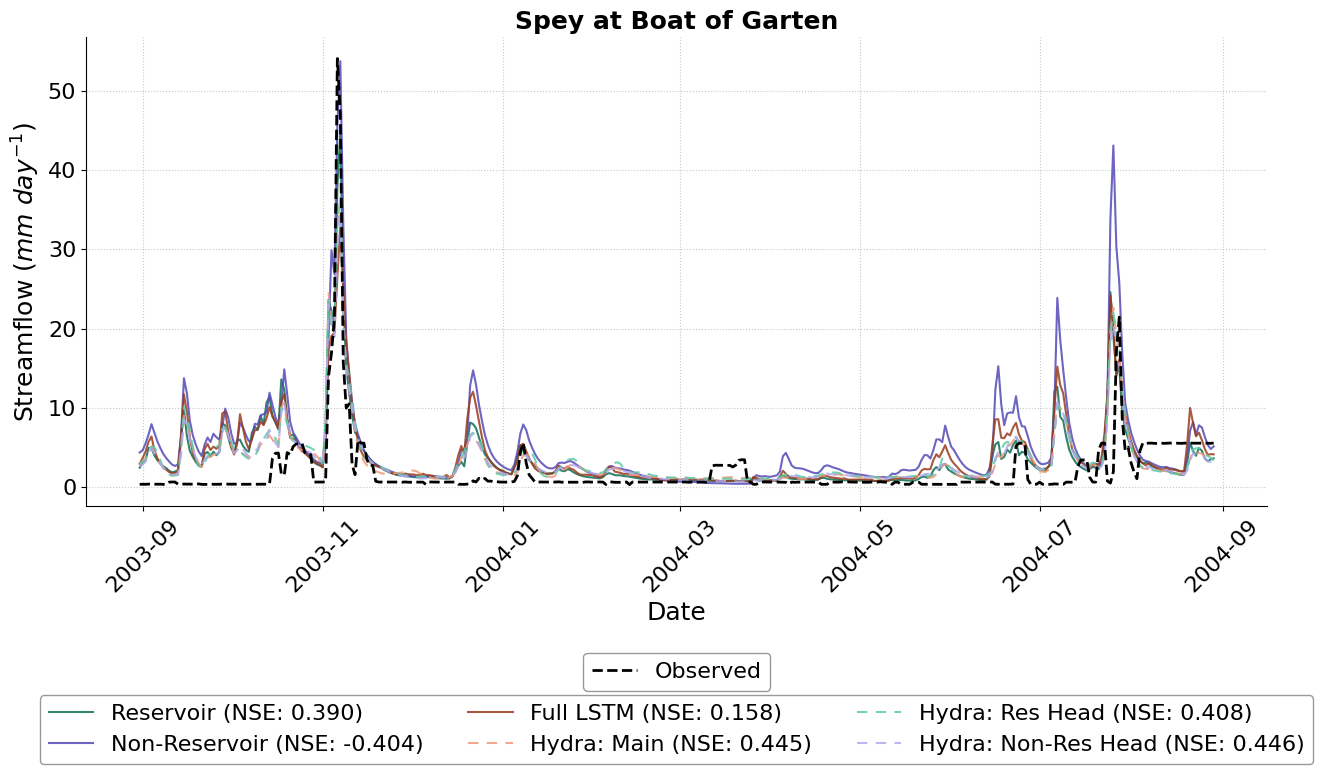

In [80]:
## Define your lists
display_names = list(MODEL_NAME_MAP.values())

# names_list = ["Hydra Reservoir Head"]
# colors_list = ["#1F4E79", "#C0392B", "#1E6B3C", "#D35400", "#6C3483"]
# 8005, 54080, 68003, 65004 Have the Non Reservoir Model perform very Badly, and Reservoir model performin a lot better
# For 8005, 68003, 65004 that gain comes solely from dampening

# 54003 Vyrnwy at Vyrnwy Reservoir
# 65004 Gwyrfai at Bontnewydd
# 8005 Spey at Boat of Garten: 102, 33 for full year, 

# 8005 is probably the best to show, its still dampening but it's a serious dampening, 34 is 2005 and works, shows that the Hydra models are oaky too,  14 is good but only the reservoir model is good
# I should report the variance in this too, to make the point of dampening, 282 for 92 day hydrograph
start_index = 282 + 23*365 

# 54003 is Vyrnwy at Vyrnwy Reservoir (41 to get to Jan 1, 24 years, 222 for 1st July), 65004 Gwyrfai at Bontnewydd (312 to get to Jan1. 21 years from start, 142 for 1st July)
# Call the function
plot_multi_model_hydrograph(
    target_gauge_id='54003', 
    models_dict= no_flow_reservoir_lagged,
    gauge_ids=test_res_tensor_metadata['gauge_id'],
    dates=test_res_tensor_metadata['init_date'],
    gauge_name = 'Spey at Boat of Garten',
    model_names=display_names,
    model_colors=MODEL_COLORS,
    start_index=start_index,
    max_timesteps= 365*1
)

# Map of KGE scores

- Get lat-lon of each test gauges
- Plot them on map of the UK
- Add KGE scores 

In [3]:

folder_path = "/perm/mokr/CamelsGB_V2/Catchment_Attributes/"
All_Static_Variables = pd.DataFrame()
# List CSV files directly in the main folder (excluding subfolders)
csv_files = [f for f in os.listdir(folder_path) if f.endswith(".csv")]

# Loop through the CSV files
for file in csv_files:
    file_path = os.path.join(folder_path, file)
    # Read the CSV file and concatenate it with the merged_df
    static_variable_group = pd.read_csv(file_path)
    All_Static_Variables = pd.concat(
        [All_Static_Variables, static_variable_group], ignore_index=True
    )

# Merge by 'gauge_id'
c = All_Static_Variables.groupby("gauge_id").sum().reset_index()

In [43]:
merged_metrics_by_results['all_gauges']['Specialist'].index
All_Static_Variables[['gauge_id', 'gauge_lat', 'gauge_lon']]

static = All_Static_Variables[['gauge_id', 'gauge_lat', 'gauge_lon']].copy()
static = static.dropna(subset=['gauge_id']).copy()
static['gauge_id'] = static['gauge_id'].astype(int).astype(str)

gauge_ids = merged_metrics_by_results['all_gauges']['Specialist'].index.astype(int).astype(str)

filtered_static = static[static['gauge_id'].isin(gauge_ids)]


In [63]:
All_Static_Variables.columns.to_list()

['gauge_id',
 'inter_high_perc',
 'inter_mod_perc',
 'inter_low_perc',
 'frac_high_perc',
 'frac_mod_perc',
 'frac_low_perc',
 'no_gw_perc',
 'low_nsig_perc',
 'nsig_low_perc',
 'benchmark_catch',
 'surfacewater_abs',
 'groundwater_abs',
 'discharges',
 'abs_agriculture_perc',
 'abs_amenities_perc',
 'abs_energy_perc',
 'abs_environmental_perc',
 'abs_industry_perc',
 'abs_watersupply_perc',
 'abs_highloss_perc',
 'abs_mediumloss_perc',
 'abs_lowloss_perc',
 'abs_verylowloss_perc',
 'num_reservoir',
 'reservoir_cap',
 'reservoir_contributing_area',
 'reservoir_normalised_upstream_capacity',
 'reservoir_he',
 'reservoir_nav',
 'reservoir_drain',
 'reservoir_wr',
 'reservoir_fs',
 'reservoir_env',
 'reservoir_nousedata',
 'reservoir_year_first',
 'reservoir_year_last',
 'gw_well_id',
 'gw_well_name',
 'gw_well_easting',
 'gw_well_northing',
 'gw_well_datum',
 'gw_well_depth',
 'aquifer',
 'daily_gwlevel_period_start',
 'daily_gwlevel_period_end',
 'daily_gwlevel_perc_complete',
 'monthly

In [70]:

 # 'num_reservoir',
 # 'reservoir_cap',
 # 'reservoir_contributing_area',
 # 'reservoir_normalised_upstream_capacity',



avg_metrics_by_results['no_flow_reservoir']['Reservoir_Embedded_LSTM'].index

# 1. Define your target gauge IDs from the results index
target_gauges = avg_metrics_by_results['no_flow_reservoir']['Reservoir_Embedded_LSTM'].index

# 1. Convert the string index to floats to match the dataframe's dtype
target_gauges_float = target_gauges.astype(float)

# 2. Define your columns
target_columns = [
    'gauge_id',
    # Not interesting variables when plotting
    # 'num_reservoir',
    # 'reservoir_cap',
    'reservoir_contributing_area',
    'reservoir_normalised_upstream_capacity',
]

# 1. Get the data columns (excluding 'gauge_id')
data_columns = [col for col in target_columns if col != 'gauge_id']

# 2. Filter rows with matching gauges, select columns, and drop rows where all metrics are NaN
reservoir_static = All_Static_Variables.copy()
mask = reservoir_static['gauge_id'].isin(target_gauges_float)

reservoir_static = (
    reservoir_static.loc[mask, target_columns]
    .dropna(subset=data_columns, how='all')
    .drop_duplicates(subset=['gauge_id'], keep='first')
)

reservoir_static

# Make joint dataframe, adding in the NSE scores of each model
avg_metrics_by_results['no_flow_reservoir']['Reservoir_Embedded_LSTM']['NSE']

# For each of the target columns, make a scatter plot of the NSE of each gauge (y axis) against the column value (x axis)

# As an extra, make scatter plot of the Delta NSE between the other models and the Non_Reservoir_LSTM, so we can normalise for 'gauge difficulty' 

gauge_id
16001    0.763789
16004    0.841484
2001     0.726721
41005    0.479756
54001    0.490740
54003   -4.408923
54005    0.685611
54028    0.808085
54032    0.542509
54057    0.517063
54080    0.581412
54095    0.558510
65004    0.881981
65006    0.877696
67001   -0.186381
67006    0.679589
67015    0.750668
67033    0.380544
68003    0.697480
8005     0.536346
8006     0.617320
83009    0.747713
Name: NSE, dtype: float64

In [77]:
import matplotlib.pyplot as plt
import pandas as pd

# ---------------------------------------------------------
# 1. Clean and prepare reservoir_static
# ---------------------------------------------------------
target_gauges = avg_metrics_by_results['no_flow_reservoir'][
    'Reservoir_Embedded_LSTM'
].index
target_gauges_float = target_gauges.astype(float)

target_columns = [
    'gauge_id',
    'reservoir_contributing_area',
    'reservoir_normalised_upstream_capacity',
]
data_columns = [col for col in target_columns if col != 'gauge_id']

reservoir_static = All_Static_Variables.copy()
mask = reservoir_static['gauge_id'].isin(target_gauges_float)

reservoir_static = (
    reservoir_static.loc[mask, target_columns]
    .dropna(subset=data_columns, how='all')
    .drop_duplicates(subset=['gauge_id'], keep='first')
)

# Convert gauge_id to string to match the model results index
reservoir_static['gauge_id'] = (
    reservoir_static['gauge_id'].astype(int).astype(str)
)
reservoir_static = reservoir_static.set_index('gauge_id')

# ---------------------------------------------------------
# 2. Extract NSE scores and build the joint DataFrame
# ---------------------------------------------------------
models_dict = avg_metrics_by_results['no_flow_reservoir']

# Extract NSE Series for all models
nse_data = {
    f'NSE_{model_name}': model_df['NSE']
    for model_name, model_df in models_dict.items()
}
nse_df = pd.DataFrame(nse_data)

# Join static attributes with NSE metrics
joint_df = reservoir_static.join(nse_df, how='inner')

# ---------------------------------------------------------
# 3. Compute Delta NSE against the Non_Reservoir_LSTM baseline
# ---------------------------------------------------------
baseline_col = 'NSE_NonReservoir_Embedded_LSTM'

delta_cols = []
if baseline_col in joint_df.columns:
    for model_name in models_dict.keys():
        col_name = f'NSE_{model_name}'
        if col_name != baseline_col:
            delta_col = f'Delta_NSE_{model_name}'
            joint_df[delta_col] = joint_df[col_name] - joint_df[baseline_col]
            delta_cols.append(delta_col)




In [78]:
models_dict.keys()

dict_keys(['Reservoir_Embedded_LSTM', 'NonReservoir_Embedded_LSTM', 'Full_Embedded_LSTM', 'Hydra_Main', 'Hydra_ResHead', 'Hydra_NonResHead'])

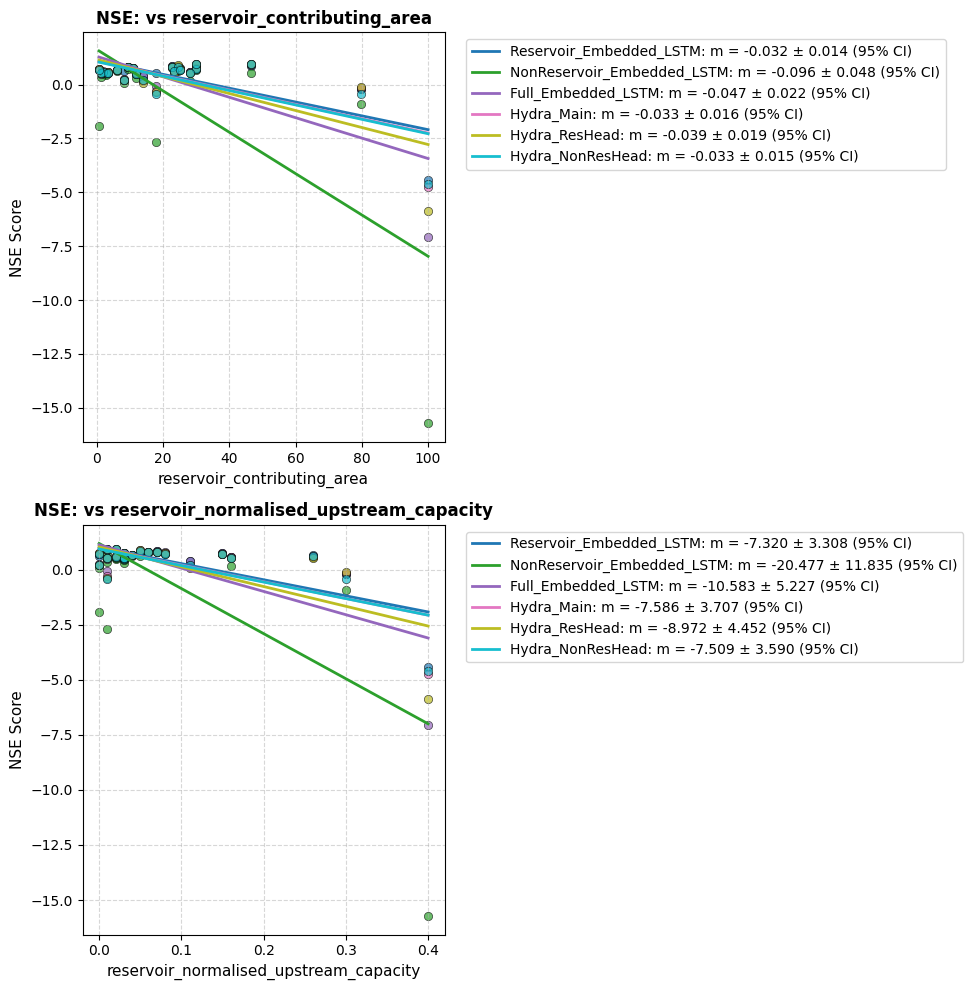

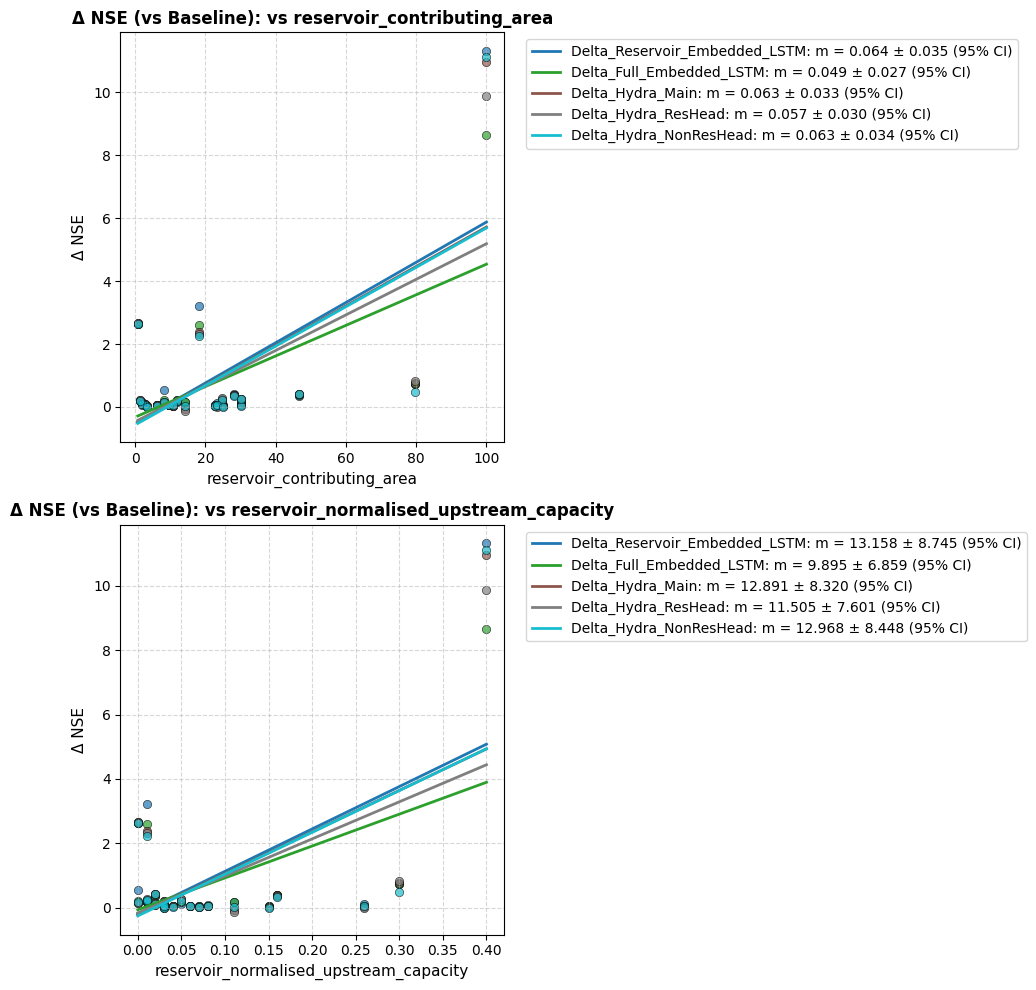

In [79]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

# ---------------------------------------------------------
# Helper function: Plot overlay scatter with regression & CI
# ---------------------------------------------------------
def plot_models_vs_attributes(df, attributes, target_metric_cols, title_prefix, ylabel):
    # Set up a distinct color palette
    colors = plt.cm.tab10(np.linspace(0, 1, len(target_metric_cols)))
    
    fig, axes = plt.subplots(
        len(attributes), 1, 
        figsize=(10, 5 * len(attributes)), 
        squeeze=False
    )

    for i, attr in enumerate(attributes):
        ax = axes[i, 0]
        
        for col, color in zip(target_metric_cols, colors):
            # Drop NaNs for this specific pair
            valid_data = df[[attr, col]].dropna()
            x = valid_data[attr].values
            y = valid_data[col].values
            
            model_name = col.replace('NSE_', '').replace('Delta_NSE_', '')
            
            if len(x) > 2:
                # Linear regression
                res = stats.linregress(x, y)
                slope = res.slope
                
                # 95% Confidence Interval for the slope: slope +/- t_crit * stderr
                # degrees of freedom = n - 2
                t_crit = stats.t.ppf(0.975, df=len(x) - 2)
                ci_half_width = t_crit * res.stderr
                
                # Format label with slope and 95% CI
                label = f"{model_name}: m = {slope:.3f} ± {ci_half_width:.3f} (95% CI)"
                
                # Scatter points
                ax.scatter(x, y, color=color, alpha=0.7, edgecolors='k', linewidth=0.5)
                
                # Line of best fit
                x_vals = np.linspace(x.min(), x.max(), 100)
                y_vals = res.intercept + slope * x_vals
                ax.plot(x_vals, y_vals, color=color, linewidth=2, label=label)
            else:
                ax.scatter(x, y, color=color, alpha=0.7, label=model_name)

        if 'Delta' in title_prefix:
            ax.axhline(0, color='grey', linestyle=':', linewidth=1)

        ax.set_xlabel(attr, fontsize=11)
        ax.set_ylabel(ylabel, fontsize=11)
        ax.set_title(f"{title_prefix}: vs {attr}", fontsize=12, fontweight='bold')
        ax.grid(True, linestyle='--', alpha=0.5)
        ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", frameon=True)

    plt.tight_layout()
    plt.show()

# ---------------------------------------------------------
# 1. Plot Raw NSE for all models
# ---------------------------------------------------------
nse_cols = [c for c in joint_df.columns if c.startswith('NSE_')]
plot_models_vs_attributes(
    df=joint_df,
    attributes=data_columns,
    target_metric_cols=nse_cols,
    title_prefix="NSE",
    ylabel="NSE Score"
)

# ---------------------------------------------------------
# 2. Plot Delta NSE for all models (vs Baseline)
# ---------------------------------------------------------

if delta_cols:
    plot_models_vs_attributes(
        df=joint_df,
        attributes=data_columns,
        target_metric_cols=delta_cols,
        title_prefix="Δ NSE (vs Baseline)",
        ylabel="Δ NSE"
    )

In [67]:
avg_metrics_by_results['no_flow_reservoir']['Reservoir_Embedded_LSTM']['NSE']

gauge_id
16001    0.763789
16004    0.841484
2001     0.726721
41005    0.479756
54001    0.490740
54003   -4.408923
54005    0.685611
54028    0.808085
54032    0.542509
54057    0.517063
54080    0.581412
54095    0.558510
65004    0.881981
65006    0.877696
67001   -0.186381
67006    0.679589
67015    0.750668
67033    0.380544
68003    0.697480
8005     0.536346
8006     0.617320
83009    0.747713
Name: NSE, dtype: float64

In [54]:
reservoir_static['gauge_id'].isin(target_gauges_float)

0       False
1       False
2       False
3       False
4       False
        ...  
5418    False
5419    False
5420    False
5421    False
5422    False
Name: gauge_id, Length: 5423, dtype: bool

In [43]:
import geopandas as gpd
import os

uk_boundary = gpd.read_file(
    "/home/mokr/Camels_GB/GB_Shape_Files/CTRY_DEC_2024_UK_BFC.shp"
)

In [125]:
# Pick model and metric to colour by
MODEL = "Hydra Specialist"
METRIC = "KGE"

# ['Specialist', 'Full LSTM', 'Hydra_Specialist', 'Hydra: Main']

# Build a scores Series with string gauge_id index
scores = merged_metrics_by_results['all_gauges'][MODEL][METRIC].copy()
scores.index = scores.index.astype(int).astype(str)

# Filter static to merged gauges and attach scores
filtered_static = All_Static_Variables.copy()
filtered_static['gauge_id'] = filtered_static['gauge_id'].astype(int).astype(str)
filtered_static = filtered_static[filtered_static['gauge_id'].isin(scores.index)]
filtered_static[METRIC] = filtered_static['gauge_id'].map(scores)

# Build GeoDataFrame
gdf_gauges = gpd.GeoDataFrame(
    filtered_static,
    geometry=gpd.points_from_xy(filtered_static["gauge_lon"], filtered_static["gauge_lat"]),
    crs="EPSG:4326",
)
if uk_boundary.crs != gdf_gauges.crs:
    gdf_gauges = gdf_gauges.to_crs(uk_boundary.crs)

# Plot
fig, ax = plt.subplots(figsize=(12, 14))
uk_boundary.plot(ax=ax, color="lightgray", edgecolor="darkgray", linewidth=1.5)

scatter = gdf_gauges.plot(
    ax=ax,
    column=METRIC,
    cmap="RdYlGn",
    vmin=-0.5, vmax=1.0,
    markersize=45,
    alpha=0.85,
    edgecolor="black",
    linewidth=0.5,
    legend=False,
)

# Colorbar
sm = plt.cm.ScalarMappable(cmap="RdYlGn", norm=plt.Normalize(vmin=-0.5, vmax=1.0))
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, shrink=0.5, pad=0.02)
cbar.set_label(f"{MODEL} — {METRIC}", fontsize=13)
cbar.ax.tick_params(labelsize=11)

ax.set_title(f"Gauge {METRIC} scores — {MODEL}", fontsize=16, fontweight="bold", pad=20)
ax.set_xlabel("Easting", fontsize=12)
ax.set_ylabel("Northing", fontsize=12)
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

IntCastingNaNError: Cannot convert non-finite values (NA or inf) to integer

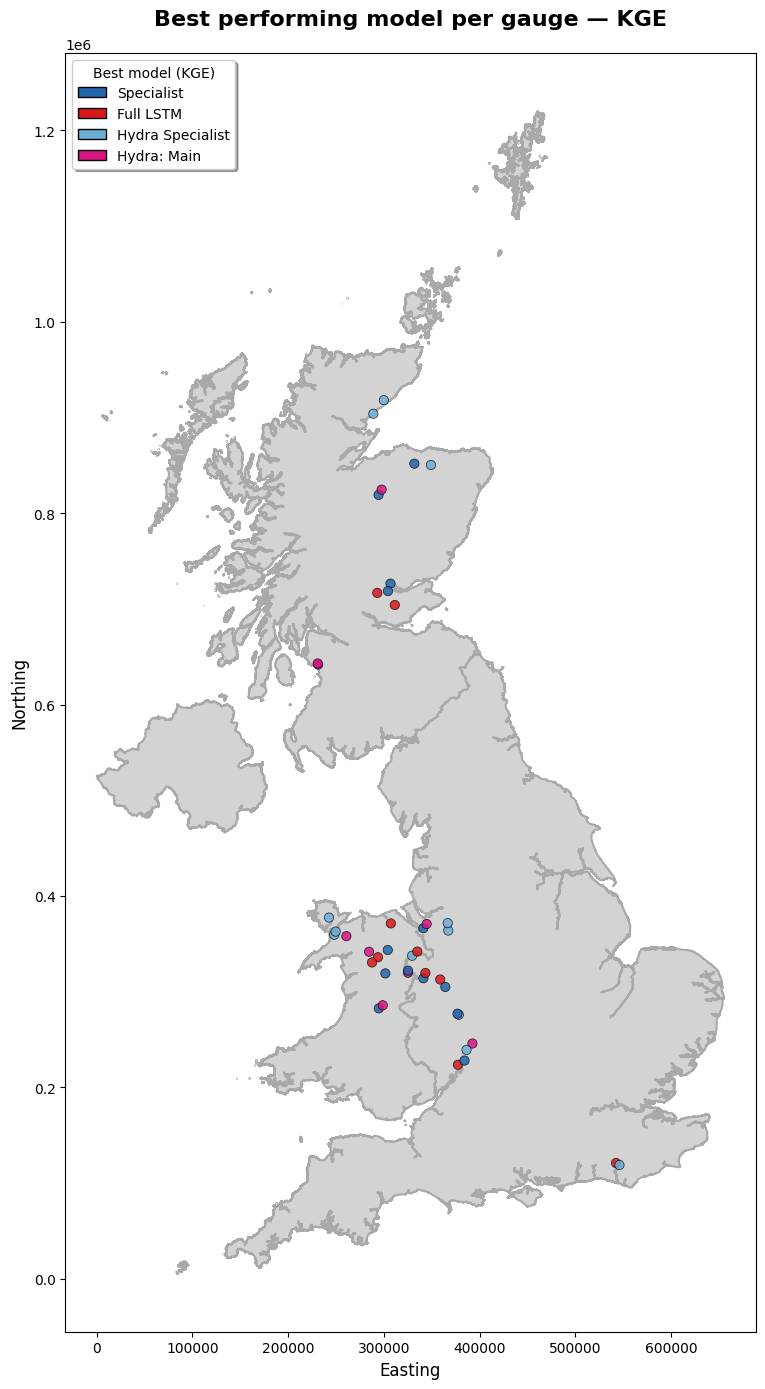


Best model counts:
best_model
Specialist          13
Hydra Specialist    12
Full LSTM           10
Hydra: Main          9
Name: count, dtype: int64


In [125]:
from matplotlib.patches import Patch
METRIC = "KGE"


models = list(merged_metrics_by_results['all_gauges'].keys())

# Build a DataFrame of scores: index=gauge_id, columns=models
scores_df = pd.DataFrame({
    model: merged_metrics_by_results['all_gauges'][model][METRIC]
    for model in models
})
scores_df.index = scores_df.index.astype(int).astype(str)

# Find best model per gauge
scores_df['best_model'] = scores_df[models].idxmax(axis=1)
scores_df['color'] = scores_df['best_model'].map(AVERAGE_MODEL_COLORS)

# Filter static and attach
filtered_static = All_Static_Variables.copy()
filtered_static['gauge_id'] = filtered_static['gauge_id'].astype(int).astype(str)
filtered_static = filtered_static[filtered_static['gauge_id'].isin(scores_df.index)]
filtered_static['best_model'] = filtered_static['gauge_id'].map(scores_df['best_model'])
filtered_static['color'] = filtered_static['gauge_id'].map(scores_df['color'])

# Build GeoDataFrame
gdf_gauges = gpd.GeoDataFrame(
    filtered_static,
    geometry=gpd.points_from_xy(filtered_static["gauge_lon"], filtered_static["gauge_lat"]),
    crs="EPSG:4326",
)
if uk_boundary.crs != gdf_gauges.crs:
    gdf_gauges = gdf_gauges.to_crs(uk_boundary.crs)

# Plot
fig, ax = plt.subplots(figsize=(12, 14))
uk_boundary.plot(ax=ax, color="lightgray", edgecolor="darkgray", linewidth=1.5)

gdf_gauges.plot(
    ax=ax,
    color=gdf_gauges['color'],
    markersize=45,
    alpha=0.85,
    edgecolor="black",
    linewidth=0.5,
)

# Legend
legend_elements = [
    Patch(facecolor=AVERAGE_MODEL_COLORS[model], edgecolor="black", label=model)
    for model in models
]
ax.legend(
    handles=legend_elements,
    title=f"Best model ({METRIC})",
    loc="upper left",
    frameon=True,
    fancybox=True,
    shadow=True,
)

ax.set_title(f"Best performing model per gauge — {METRIC}", fontsize=16, fontweight="bold", pad=20)
ax.set_xlabel("Easting", fontsize=12)
ax.set_ylabel("Northing", fontsize=12)
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

print("\nBest model counts:")
print(scores_df['best_model'].value_counts())

In [ ]:
scores_df

AVERAGE_MODEL_COLORS = {
    "Specialist":       "#2166ac",  # solid blue
    "Full LSTM":        "#d6191b",  # solid red
    "Hydra Specialist": "#6baed6",  # lighter blue (dotted)
    "Hydra: Main":      "#d61582",  # lighter red/salmon (dotted)
}

In [70]:
for gauge in avg_metrics_by_results['no_flow_reservoir']['Reservoir_Embedded_LSTM'].index.values:
    
    print(gauge, get_basin_name(int(gauge), csv_base_path="/perm/mokr/Scaled_CamelsGB_V2"))


16001 Earn at Kinkell Bridge
16004 Earn at Forteviot Bridge
2001 Helmsdale at Kilphedir
41005 Ouse at Gold Bridge
54001 Severn at Bewdley
54003 Vyrnwy at Vyrnwy Reservoir
54005 Severn at Montford
54028 Vyrnwy at Llanymynech
54032 Severn at Saxons Lode
54057 Severn at Haw Bridge
54080 Severn at Dolwen
54095 Severn at Buildwas
65004 Gwyrfai at Bontnewydd
65006 Seiont at Peblic Mill
67001 Dee at Bala
67006 Alwen at Druid
67015 Dee at Manley Hall
67033 Dee at Chester Suspension Bridge
68003 Dane at Rudheath
8005 Spey at Boat of Garten
8006 Spey at Boat o Brig
83009 Garnock at Kilwinning


In [1]:

folder_path = "/perm/mokr/CamelsGB_V2/Catchment_Attributes/"
All_Static_Variables = pd.DataFrame()
# List CSV files directly in the main folder (excluding subfolders)
csv_files = [f for f in os.listdir(folder_path) if f.endswith(".csv")]

# Loop through the CSV files
for file in csv_files:
    file_path = os.path.join(folder_path, file)
    # Read the CSV file and concatenate it with the merged_df
    static_variable_group = pd.read_csv(file_path)
    All_Static_Variables = pd.concat(
        [All_Static_Variables, static_variable_group], ignore_index=True
    )

# Merge by 'gauge_id'
c = All_Static_Variables.groupby("gauge_id").sum().reset_index()


NameError: name 'pd' is not defined

# Hydrographs

In [45]:
def get_basin_name(basin_idx, csv_base_path="/perm/mokr/Scaled_CamelsGB_V2"):
    # Split by underscore and take the first part as location
    csv_filename = f"normalised_static_data.csv"
    csv_path = os.path.join(csv_base_path, csv_filename)
    df = pd.read_csv(csv_path, engine="python")
    gauge_name = df[df["gauge_id"] == basin_idx]["gauge_name"].values[0]

    return gauge_name

In [46]:
# Font sizes for paper-quality plots
TITLE_FONTSIZE = 20
LABEL_FONTSIZE = 18
TICK_FONTSIZE = 16
LEGEND_FONTSIZE = 14

# Color scheme
ECMWF_COLORS = ["#2E86AB", "#F18F01", "#06A77D", "#A23B72", "#FFD700"]
TARGET_COLOR = "black"

# Model name mappings (customize as needed)


def plot_model_comparison_timeseries(
    batch_outputs,
    model_names,
    gauge_name,
    start=0,
    end=365,
    model_name_map=None,
    colors=None,
    figsize=(15, 8),
    save_path=None,
    dpi=300,
):
    """
    Plot time series comparison of multiple models against target with paper-ready formatting.

    Parameters:
    -----------
    batch_outputs : dict
        Dictionary with model names as keys, containing (output, target) tuples
    model_names : list
        List of model names to plot
    gauge_name : str
        Name of the gauge/catchment for the title
    start : int
        Starting time step (default: 0)
    end : int
        Ending time step (default: 365)
    model_name_map : dict, optional
        Dictionary to rename models in legend. If None, uses MODEL_NAME_MAP
    colors : list, optional
        List of colors for models. If None, uses ECMWF_COLORS
    figsize : tuple
        Figure size (width, height) in inches
    save_path : str, optional
        Path to save figure. If None, displays instead
    dpi : int
        Resolution for saved figure (default: 300)
    """
    if model_name_map is None:
        model_name_map = MODEL_NAME_MAP

    if colors is None:
        colors = ECMWF_COLORS

    # Create figure
    fig, ax = plt.subplots(figsize=figsize)

    # Get target - take the last timestep for each sequence
    target = batch_outputs[model_names[0]][0][1][start:end, -1].cpu().numpy()

    # Plot target in black with thicker line
    ax.plot(target, label="Observed", linewidth=3, color=TARGET_COLOR, zorder=10)

    # Plot each model's output
    for idx, model_name in enumerate(model_names):
        output = batch_outputs[model_name][0][0][start:end, -1].cpu().numpy()

        # Customize line style based on model name
        if "Full" in model_name or "Hydra" in model_name:
            linestyle = "--"
        else:
            linestyle = "-"

        # Use color from palette
        color = colors[idx % len(colors)]

        # Use mapped name if available
        display_name = model_name_map.get(model_name, model_name)

        ax.plot(
            output,
            label=display_name,
            linewidth=2.5,
            linestyle=linestyle,
            color=color,
            alpha=0.85,
        )

    # Labels and title with larger fonts
    ax.set_title(
        f"Model Predictions for {gauge_name}",
        fontsize=TITLE_FONTSIZE,
        fontweight="bold",
        pad=15,
    )
    ax.set_xlabel("Time Step (days)", fontsize=LABEL_FONTSIZE, fontweight="bold")
    ax.set_ylabel("Streamflow (mm/day)", fontsize=LABEL_FONTSIZE, fontweight="bold")

    # Larger tick labels
    ax.tick_params(axis="both", which="major", labelsize=TICK_FONTSIZE)

    # Larger legend with better positioning
    ax.legend(
        fontsize=LEGEND_FONTSIZE,
        frameon=True,
        shadow=True,
        loc="best",
        framealpha=0.9,
        ncol=1,
    )

    # Grid with better visibility
    ax.grid(True, alpha=0.4, linestyle="--", linewidth=0.8)

    plt.tight_layout()

    # Save or show
    if save_path:
        fig.savefig(save_path, dpi=dpi, bbox_inches="tight")
        print(f"Saved: {save_path}")
    else:
        plt.show()

    return fig

In [47]:
gauges = np.unique(test_res_tensor_metadata["gauge_id"])
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
num_plots = 12

WARMUP = 10
MAX_BATCHES = 1

for i in range(num_plots):
    gauge = np.random.choice(gauges)
    gauge_name = get_basin_name(int(gauge))
    dataloader = gauge_loaders[gauge]

    batch_outputs = process_validation_batches(
        dataloader,
        model_names,
        flow_models,
        WARMUP,
        scaler_river,
        device=DEVICE,
        time_interval=1,
        max_batches=MAX_BATCHES,
        use_flow=True,
    )

    structured_batch_outputs = collect_validation_results(batch_outputs)
    
    fig = plot_model_comparison_timeseries(
        structured_batch_outputs, model_names, gauge_name, start=0, end=195
    )

NameError: name 'test_res_tensor_metadata' is not defined

In [ ]:
batch_outputs

In [ ]:
def collect_validation_results(validation_generator):
    """
    Consumes the validation generator and formats the outputs into a nested 
    dictionary for the plotting function.
    
    Returns:
    --------
    dict
        Format: {model_name: [(output_batch_0, target_batch_0), (output_batch_1, target_batch_1), ...]}
    """
    batch_outputs = {}
    
    # Iterate through the yielded batches from your validation function
    for batch_results, target in validation_generator:
        
        for model_name, output in batch_results.items():
            # Initialize the list for the model if it doesn't exist yet
            if model_name not in batch_outputs:
                batch_outputs[model_name] = []
                
            # Append the (output, target) tuple for this specific batch
            batch_outputs[model_name].append((output, target))
            
    return batch_outputs

# 1. Initialize your generator
# (Make sure to pass all your specific arguments like models, dataloader, etc.)
validation_gen = process_validation_batches(
    dataloader,
    model_names,
    flow_models,
    WARMUP,
    scaler_river,
    device=DEVICE,
    time_interval=1,
    max_batches=MAX_BATCHES,
    use_flow=True,
)


# 2. Collect and structure the data using the wrapper
print("Collecting batch outputs...")
structured_batch_outputs = collect_validation_results(validation_gen)

# 3. Plot the results using the corrected plotting function
# (This will plot the first sequence in the first batch)
print("Generating plot...")
fig = plot_model_comparison_timeseries(
    structured_batch_outputs, model_names, gauge_name, start=0, end=95
)

In [ ]:
gauge

In [ ]:
def calculate_kge(predictions, targets):

    eps = 1e-6
    """Calculate KGE components (alpha, beta, and correlation)"""
    # Correlation coefficient
    pred_mean = np.mean(predictions)
    target_mean = np.mean(targets)

    numerator = np.mean((predictions - pred_mean) * (targets - target_mean))
    pred_std = np.sqrt(np.mean((predictions - pred_mean) ** 2))
    target_std = np.sqrt(np.mean((targets - target_mean) ** 2))
    correlation = numerator / ((pred_std * target_std) + eps)

    # Alpha (variability ratio)
    gamma = (pred_std / (pred_mean + eps)) / (target_std / (target_mean + eps))

    # Beta (bias ratio)
    beta = pred_mean / (target_mean + eps)

    kge = 1 - np.sqrt((correlation - 1) ** 2 + (gamma - 1) ** 2 + (beta - 1) ** 2)
    # print(gamma, beta, correlation)
    return kge


def calculate_nse(predictions, targets):
    eps = 1e-8
    """Calculate Nash-Sutcliffe Efficiency"""
    numerator = np.mean((predictions - targets) ** 2)
    denominator = np.mean((targets - np.mean(targets)) ** 2)
    return 1 - ((numerator + eps) / (denominator + eps))

In [ ]:
import warnings

max_batches = 15
seed = 44
warmup = 0
loss_interval = 2
# This will suppress all warnings that occur while the function is running
with warnings.catch_warnings():
    warnings.simplefilter("ignore")

    # Reservoir model
    reservoir_outputs, targets, gauges, countries = validate_model(
        Reservoir_Embedded_LSTM,
        test_dataloader,
        criterion,
        max_batches,
        warmup,
        10,
        time_interval=15,
        share_location=True,
    )
    unnormalized_reservoir_outputs = streamflow_scaler.inverse_transform(
        reservoir_outputs.detach().numpy()
    )
    unnormalized_reservoir_outputs = np.clip(
        unnormalized_reservoir_outputs, a_min=0, a_max=None
    )  # <-- Clip below 0
    unnormalized_targets = streamflow_scaler.inverse_transform(targets.detach().numpy())

    # Non-reservoir model
    nonreservoir_outputs, targets = validate_model(
        NonReservoir_Embedded_LSTM,
        test_dataloader,
        criterion,
        max_batches,
        warmup,
        loss_interval,
        time_interval=15,
    )
    unnormalized_nonreservoir_outputs = streamflow_scaler.inverse_transform(
        nonreservoir_outputs.detach().numpy()
    )
    unnormalized_nonreservoir_outputs = np.clip(
        unnormalized_nonreservoir_outputs, a_min=0, a_max=None
    )  # <-- Clip

    # Full model
    full_outputs, targets = validate_model(
        Full_Embedded_LSTM,
        test_dataloader,
        criterion,
        max_batches,
        warmup,
        loss_interval,
        time_interval=15,
    )
    unnormalized_full_outputs = streamflow_scaler.inverse_transform(
        full_outputs.detach().numpy()
    )
    unnormalized_full_outputs = np.clip(
        unnormalized_full_outputs, a_min=0, a_max=None
    )  # <-- Clip

    # Hydra model
    hydra_res_outputs, targets = validate_model(
        [Hydra_Body, Hydra_ResHead],
        test_dataloader,
        criterion,
        max_batches,
        warmup,
        loss_interval,
        time_interval=15,
    )
    unnormalized_hydra_res_outputs = streamflow_scaler.inverse_transform(
        hydra_res_outputs.detach().numpy()
    )
    unnormalized_hydra_res_outputs = np.clip(
        unnormalized_hydra_res_outputs, a_min=0, a_max=None
    )  # <-- Clip

    # set_seeds(seed=42)
    # hydra_res_outputs, targets = validate_model(Hydra_Main, test_dataloader, criterion, max_batches, warmup, loss_interval, time_interval = 15)
    # unnormalized_hydra_res_outputs = streamflow_scaler.inverse_transform(hydra_res_outputs.detach().numpy())


import matplotlib.pyplot as plt

for i in range(1, max_batches):

    plt.figure(figsize=(12, 6))

    kge_reservoir = calculate_kge(
        unnormalized_reservoir_outputs[i], unnormalized_targets[i]
    )
    kge_nonreservoir = calculate_kge(
        unnormalized_nonreservoir_outputs[i], unnormalized_targets[i]
    )
    kge_full = calculate_kge(unnormalized_full_outputs[i], unnormalized_targets[i])
    kge_hydra = calculate_kge(
        unnormalized_hydra_res_outputs[i], unnormalized_targets[i]
    )

    nse_reservoir = calculate_nse(
        unnormalized_reservoir_outputs[i], unnormalized_targets[i]
    )
    nse_nonreservoir = calculate_nse(
        unnormalized_nonreservoir_outputs[i], unnormalized_targets[i]
    )
    nse_full = calculate_nse(unnormalized_full_outputs[i], unnormalized_targets[i])
    nse_hydra = calculate_nse(
        unnormalized_hydra_res_outputs[i], unnormalized_targets[i]
    )

    model_names = [
        "Reservoir_Embedded_LSTM",
        "NonReservoir_Embedded_LSTM",
        "Full_Embedded_LSTM",
        "Hydra_ResHead",
        "Hydra_Main",
    ]
    colors = ["orange", "green", "red", "purple", "blue"]

    # Plot targets and outputs with metrics in legend labels
    plt.plot(unnormalized_targets[i], label="Target", color="black", linewidth=2)
    plt.plot(
        unnormalized_reservoir_outputs[i],
        label=f"Reservoir-LSTM (NSE: {nse_reservoir:.3f}, KGE: {kge_reservoir:.3f})",
        color="orange",
        linestyle="--",
        linewidth=2,
    )
    plt.plot(
        unnormalized_nonreservoir_outputs[i],
        label=f"NonReservoir-LSTM (NSE: {nse_nonreservoir:.3f}, KGE: {kge_nonreservoir:.3f})",
        color="green",
        linestyle="--",
        linewidth=2,
    )
    plt.plot(
        unnormalized_full_outputs[i],
        label=f"Full-LSTM (NSE: {nse_full:.3f}, KGE: {kge_full:.3f})",
        color="red",
        linewidth=2,
        linestyle="--",
    )
    plt.plot(
        unnormalized_hydra_res_outputs[i],
        label=f"Hydra (NSE: {nse_hydra:.3f}, KGE: {kge_hydra:.3f})",
        color="purple",
        linewidth=2,
        linestyle="--",
    )

    # Add labels and title
    plt.title(f"Streamflow for Basin: {gauges[i]}")
    plt.xlabel("Date")
    plt.ylabel("Specific Discharge ($ms^{-1}$)")
    plt.legend()
    plt.grid(True, which="both", linestyle="--", linewidth=0.5)

    plt.tight_layout()
    plt.show()

In [ ]:
# samples = sample_basin_date_pairs('NonReservoirs_Train', n_samples=10, num_basins=90)

for basin in [
    "hysets_11443000"
]:  # basins hysets_12457000 1976 hysets_12199000 hysets_11443000 camelsch_3019
    region = basin.split("_")[0]

    # Static data

    basin_caravan_attributes = Caravan_Attributes[region][
        Caravan_Attributes[region]["gauge_id"] == basin
    ].copy()
    basin_hydroatlas_attributes = Hydroatlas_Attributes[region][
        Hydroatlas_Attributes[region]["gauge_id"] == basin
    ].copy()
    basin_other_attributes = Other_Attributes[region][
        Other_Attributes[region]["gauge_id"] == basin
    ].copy()

    static_df = pd.concat(
        [basin_caravan_attributes, basin_hydroatlas_attributes, basin_other_attributes],
        axis=1,
    )
    static_df = static_df.select_dtypes(include=["number"])
    static_df = static_df.loc[:, static_df.columns.isin(ordered_static_cols)]
    static_df = static_df.reindex(
        columns=ordered_static_cols
    )  # Ensure consistent column order
    static_input = torch.tensor(
        static_df.values, dtype=torch.float32
    )  # shape: (1, num_features)

    # Temporal data
    start = pd.to_datetime("1956-01-01")
    end = start + pd.Timedelta(days=365)
    basin_temporal = group_datasets[basin].sel(date=slice(start, end))

    plot_dates = basin_temporal.date.values

    if "potential_evaporation_sum_ERA5_LAND" in basin_temporal:
        basin_temporal = basin_temporal.rename(
            {"potential_evaporation_sum_ERA5_LAND": "potential_evaporation_sum"}
        )

    basin_temporal_input = basin_temporal[ordered_temporal_vars]
    targets = basin_temporal["streamflow"]
    # temporal_input = basin_temporal_input.drop_vars('streamflow')

    # Prepare tensors for the model
    temporal_np = basin_temporal_input.to_array().transpose("date", "variable").values
    temporal_input = torch.tensor(temporal_np, dtype=torch.float32).unsqueeze(0)
    target = torch.tensor(targets.values, dtype=torch.float32).unsqueeze(0)

    temporal_scaled, static_scaled, targets_scaled, _ = scale_data(
        temporal_tensor=temporal_input,
        static_tensor=static_input,
        targets_tensor=target,
        scaler_dir=SCALER_DIRECTORY,
        device="cpu",
    )

    models = [
        Reservoir_Embedded_LSTM,
        NonReservoir_Embedded_LSTM,
        Full_Embedded_LSTM,
        [Hydra_Body, Hydra_ResHead],
        Hydra_Main,
    ]
    model_names = [
        "Reservoir_Embedded_LSTM",
        "NonReservoir_Embedded_LSTM",
        "Full_Embedded_LSTM",
        "Hydra_ResHead",
        "Hydra_Main",
    ]
    colors = ["orange", "green", "red", "purple", "blue"]

    models = [NonReservoir_Embedded_LSTM, Full_Embedded_LSTM, Hydra_Main]
    model_names = ["NonReservoir_Embedded_LSTM", "Full_Embedded_LSTM", "Hydra_Main"]
    colors = ["green", "red", "blue"]

    plt.figure(figsize=(12, 6))

    # Plot each model
    for i, (model, name, color) in enumerate(zip(models, model_names, colors)):
        # Run the model pipeline
        if isinstance(model, list):  # Handle the Hydra case
            model_outputs = run_model_pipeline(
                model, static_scaled, temporal_scaled
            ).squeeze(-1)
        else:
            model_outputs = run_model_pipeline(
                model, static_scaled, temporal_scaled
            ).squeeze(-1)

        # Unnormalize outputs
        unnormalized_outputs = streamflow_scaler.inverse_transform(
            model_outputs.detach().numpy()
        )
        unnormalized_outputs = np.clip(unnormalized_outputs, a_min=0, a_max=None)

        # Plot the line
        kge = calculate_nse(unnormalized_outputs, targets.values)
        calculate_kge(unnormalized_outputs, targets.values)
        # Plot the line with KGE in the label
        plt.plot(
            plot_dates,
            unnormalized_outputs.squeeze(),
            linestyle="--",
            label=f"{name} (NSE: {kge:.3f})",
            color=color,
        )

    # Plot observed streamflow
    plt.plot(
        plot_dates,
        targets.values,
        label="Observed Streamflow",
        color="black",
        linewidth=2,
    )

    plt.xlabel("Date")
    plt.ylabel("Specific Discharge ($ms^{-1}$)")
    plt.legend()

    plt.title(
        f"Predicted vs Target Streamflow for Basin: {basin}, Start Date: {start.strftime('%Y-%m-%d')}"
    )

    # A more robust title if you comment out predictions:
    plt.title(
        f"Observed Streamflow for Basin: {basin}\nStart Date: {start.strftime('%Y-%m-%d')}"
    )

    plt.grid(
        True, which="both", linestyle="--", linewidth=0.5
    )  # Add grid for better readability
    plt.tight_layout()
    plt.show()